# Ruta de Empleabilidad de Barranquilla: ¿dónde y cómo mejorar la calidad del registro?

**Proyecto aplicado de Analítica y Toma de Decisiones** · Fuente: Secretaría de Desarrollo Económico de Barranquilla (extracción 22-nov-2026)

Este notebook integra las cuatro fases del proceso analítico:

| Fase | Contenido | Secciones |
|---|---|---|
| 1 | Definición del problema, métricas y fuentes | 1 |
| 2 | Preparación y análisis de datos (limpieza, EDA, modelado) | 2 a 6 |
| 3 | Visualización (dashboard interactivo) | 7 (datos exportados a `salidas/`) y `dashboard.html` |
| 4 | Evaluación de decisiones (escenarios, sensibilidad, recomendación) | 8 |

El estilo de código sigue los notebooks de referencia del curso (*Análisis Predictivo en BI*: regresión, clasificación y segmentación): mismos nombres de variables en español, semilla `2026`, partición 70/30 estratificada y comparación de modelos por AUC.

Librerías: `pandas`, `numpy`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn`. `statsmodels` y `xgboost` son **opcionales**: si están instaladas se usan para contrastar resultados; si no, el notebook corre igual con alternativas de scikit-learn.

In [1]:
import importlib.util
import os
import unicodedata

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Librerías opcionales (el notebook corre sin ellas)
HAY_XGB = importlib.util.find_spec("xgboost") is not None
HAY_SM = importlib.util.find_spec("statsmodels") is not None
if HAY_XGB:
    from xgboost import XGBClassifier

SEMILLA = 2026
AZUL, NARANJA, MORADO = "#2a78d6", "#eb6834", "#790cee"

sns.set_theme(style="whitegrid", font_scale=1.1)
pd.set_option("display.precision", 3)  # mostrar los resultados con 3 decimales
pd.set_option("display.max_columns", 30)

os.makedirs("figuras", exist_ok=True)
os.makedirs("salidas", exist_ok=True)


def guardar(nombre):
    # Guarda la figura actual en figuras/ (se reutiliza en el documento y las diapositivas)
    plt.savefig(f"figuras/{nombre}.png", dpi=160, bbox_inches="tight")

# 1 Fase 1: definición del problema

## 1.1 Contexto

La **Ruta de Empleabilidad** es el registro de oferentes (personas que buscan empleo) que la Secretaría de Desarrollo Económico de Barranquilla opera en cinco puntos de atención. Una persona puede registrarse de dos formas:

- **Autoregistro**: lo llena ella misma en línea.
- **Agencia**: un orientador la atiende y la registra.

Para que la Ruta pueda **orientar y conectar** a una persona con una vacante, el registro debe tener al menos su **situación laboral** y su **nivel de estudio**. Sin esos dos datos no se puede perfilar ni intermediar.

## 1.2 Problema

> **¿Qué canales, puntos de atención y momentos del día generan registros incompletos, y qué intervención de costo razonable permite aumentar la proporción de registros útiles para la intermediación laboral?**

**Decisión que se apoya:** cómo repartir el esfuerzo de la Secretaría entre (a) rediseñar o validar el autoregistro, (b) trasladar parte del registro a atención asistida y (c) hacer seguimiento focalizado a los registros con mayor probabilidad de quedar incompletos.

## 1.3 Métricas

| Métrica | Definición | Por qué es relevante |
|---|---|---|
| **Tasa de registro útil** (KPI principal) | % de registros con situación laboral **y** nivel de estudio informados | Es el insumo mínimo para perfilar e intermediar |
| Registros mensuales | Conteo por mes y punto | Dimensiona la demanda de atención |
| % autoregistro | Registros por autoregistro / total | Principal palanca de gestión (canal) |
| Tasa de actualización | % que actualiza su perfil después de registrarse | Mide si el sistema sirve para hacer seguimiento |
| % población prioritaria | Desempleados, primer empleo y cesantes / registros con situación informada | Define a quién debe llegar la política |
| Costo por registro útil adicional | Costo de la intervención / aumento de registros útiles | Compara intervenciones en términos económicos |

## 1.4 Fuentes de datos

| Fuente | Uso | Estado |
|---|---|---|
| **Ruta de Empleabilidad, Secretaría de Desarrollo Económico de Barranquilla** (23.353 registros, ene-2020 a ago-2022) | Base del análisis | **Usada** |
| DANE, Gran Encuesta Integrada de Hogares (GEIH): desempleo en Barranquilla A.M. | Contextualizar si el volumen de registros sigue el ciclo del mercado laboral | Recomendada como ampliación (no integrada) |
| DANE, proyecciones de población por municipio | Pasar de conteos a tasas por 100.000 habitantes | Recomendada como ampliación (no integrada) |
| Servicio Público de Empleo (SPE), estadísticas de oferentes y vacantes | Comparar la Ruta con el registro nacional | Recomendada como ampliación (no integrada) |

> **Nota:** el proyecto se apoya en una sola fuente primaria. Las otras tres se proponen como ampliación; si el grupo las descarga, se integran uniendo por mes.

## 1.5 Diccionario de datos original

| Columna | Descripción |
|---|---|
| `Tipo Documento` | Cédula, tarjeta de identidad, DNI extranjero, PEP |
| `Canal de Registro` | Autoregistro o Agencia |
| `Edad`, `Rango Edad`, `Género` | Datos demográficos |
| `Nivel de Estudio`, `Título Homologado` | Formación (el título es texto libre) |
| `Ciudad de Residencia`, `Zona` | Ubicación (Urbano / Rural) |
| `Fecha Registro`, `Fecha Actualización` | Texto `dd/mm/aaaa hh:mm:ss a.m.` |
| `Programa de Gobierno`, `Condiciones Especiales` | Vinculación a programas y condiciones (víctimas, discapacidad, etc.) |
| `Situación Laboral` | Desempleado, Primer Empleo, Empleado, etc. (`NO REGISTRA` si no la informó) |
| `Mes`, `Año` | Periodo de reporte (`Año` viene como `2.022` por el separador de miles) |
| `Punto Atención` | Cinco puntos de atención |

In [2]:
# Los datos originales se guardan en datos/ruta_empleabilidad.csv
RUTA_CSV = "datos/ruta_empleabilidad.csv"

crudo = pd.read_csv(RUTA_CSV, encoding="utf-8-sig")  # utf-8-sig elimina la marca BOM del encabezado
print(f"Filas: {crudo.shape[0]:,} · Columnas: {crudo.shape[1]}")
crudo.head()

Filas: 23,353 · Columnas: 17


,Tipo Documento,Canal de Registro,Edad,Género,Nivel de Estudio,Título Homologado,Ciudad de Residencia,Fecha Registro,Programa de Gobierno,Condiciones Especiales,Situación Laboral,Fecha Actualización,Zona,Mes,Año,Punto Atención,Rango Edad
0,Cédula de Ciudadanía,Autoregistro,23,M,NaN,NaN,BARRANQUILLA,07/01/2022 10:30:40 a.m.,NaN,NaN,NO REGISTRA,07/01/2022 10:30:40 a.m.,NaN,1,2.022,Barrios San José,18 - 28
1,Cédula de Ciudadanía,Autoregistro,42,M,NaN,NaN,BARRANQUILLA,24/03/2022 06:25:29 p.m.,NaN,NaN,NO REGISTRA,24/03/2022 06:25:29 p.m.,NaN,3,2.022,Barrios San José,40 - 50
2,Cédula de Ciudadanía,Autoregistro,19,F,NaN,NaN,BARRANQUILLA,24/03/2022 11:06:07 p.m.,NaN,NaN,NO REGISTRA,24/03/2022 11:06:07 p.m.,NaN,3,2.022,Barrios San José,18 - 28
3,Cédula de Ciudadanía,Autoregistro,21,M,NaN,NaN,BARRANQUILLA,23/03/2022 03:24:09 a.m.,NaN,NaN,NO REGISTRA,23/03/2022 03:24:09 a.m.,NaN,3,2.022,Barrios San José,18 - 28
4,Cédula de Ciudadanía,Autoregistro,36,M,NaN,NaN,BARRANQUILLA,06/03/2022 02:03:41 p.m.,NaN,NaN,NO REGISTRA,06/03/2022 02:03:41 p.m.,NaN,3,2.022,Barrios San José,29 - 39


# 2 Fase 2: preparación de los datos

## 2.1 Diagnóstico de calidad

Antes de limpiar se mide qué tan completa está cada columna. Además de los nulos reales, se cuentan los valores que significan "sin dato" (`ND` y `NO REGISTRA`).

In [3]:
calidad = pd.DataFrame({
    "nulos": crudo.isna().sum(),
    "pct_nulos": crudo.isna().mean() * 100,
    "sin_dato_ND_NO_REGISTRA": [crudo[c].isin(["ND", "NO REGISTRA"]).sum() for c in crudo.columns],
    "valores_unicos": crudo.nunique(),
})
calidad["pct_sin_dato_total"] = (calidad["nulos"] + calidad["sin_dato_ND_NO_REGISTRA"]) / len(crudo) * 100
print("Filas duplicadas exactas:", crudo.duplicated().sum())
calidad.sort_values("pct_sin_dato_total", ascending=False)

Filas duplicadas exactas: 0


,nulos,pct_nulos,sin_dato_ND_NO_REGISTRA,valores_unicos,pct_sin_dato_total
Condiciones Especiales,22453,96.146,0,59,96.146
Programa de Gobierno,21599,92.489,0,18,92.489
Título Homologado,2588,11.082,5597,6295,35.049
Nivel de Estudio,2573,11.018,5548,11,34.775
Situación Laboral,156,0.668,7563,6,33.054
Zona,2485,10.641,5232,3,33.045
Ciudad de Residencia,6,0.026,0,31,0.026
Tipo Documento,0,0.000,0,4,0.000
Género,0,0.000,0,2,0.000
Fecha Registro,0,0.000,0,23310,0.000


## 2.2 Limpieza

Problemas encontrados y decisión tomada:

| Problema | Decisión |
|---|---|
| `Año` aparece como `2.022` (separador de miles leído como decimal) | Multiplicar por 1.000 y convertir a entero |
| Fechas en texto con `a.m.` / `p.m.` | Convertir a `datetime` con formato explícito |
| `Situación Laboral` nula | Tratar como `NO REGISTRA` (el usuario no la informó) |
| `Nivel de Estudio` = `ND` o nulo | Unificar en `Sin dato` y crear escala ordinal 1 a 10 |
| `Zona` = `ND` o nulo | Unificar en `Sin dato` |
| `Programa de Gobierno` con valores repetidos (`A, A`) | Reducir a indicador 0/1 (`tiene_programa`) |
| `Título Homologado` con 6.295 variantes de escritura | Normalizar (minúsculas, sin tildes) y reportar la reducción; no se usa en los modelos |
| Registros anteriores a 2020 (reactivaciones de usuarios antiguos) | Se conservan y se marcan con `registro_previo_2020` |

In [4]:
df = crudo.drop_duplicates().copy()
df.columns = [
    "tipo_doc", "canal", "edad", "genero", "nivel_estudio", "titulo", "ciudad",
    "fecha_registro", "programa", "condicion", "sit_laboral", "fecha_actualizacion",
    "zona", "mes", "anio", "punto", "rango_edad",
]

# 1) Año: 2.022 -> 2022
df["anio"] = (df["anio"] * 1000).round().astype(int)


# 2) Fechas en texto "dd/mm/aaaa hh:mm:ss a.m." -> datetime
def a_fecha(serie):
    texto = serie.str.replace("a.m.", "AM", regex=False).str.replace("p.m.", "PM", regex=False)
    return pd.to_datetime(texto, format="%d/%m/%Y %I:%M:%S %p", errors="coerce")


df["fecha_registro"] = a_fecha(df["fecha_registro"])
df["fecha_actualizacion"] = a_fecha(df["fecha_actualizacion"])
df["periodo"] = pd.to_datetime({"year": df["anio"], "month": df["mes"], "day": 1})

# 3) Situación laboral, nivel de estudio y zona: unificar "sin dato"
df["sit_laboral"] = df["sit_laboral"].fillna("NO REGISTRA")
df["nivel_estudio"] = df["nivel_estudio"].fillna("Sin dato").replace("ND", "Sin dato")
df["zona"] = df["zona"].fillna("Sin dato").replace("ND", "Sin dato")

orden_nivel = {
    "Básica Primaria(1-5)": 1, "Básica Secundaria(6-9)": 2, "Media(10-13)": 3,
    "Técnica Laboral": 4, "Técnica Profesional": 5, "Tecnológica": 6,
    "Universitaria": 7, "Especialización": 8, "Maestría": 9, "Doctorado": 10,
}
df["nivel_ord"] = df["nivel_estudio"].map(orden_nivel)  # NaN si "Sin dato"

# 4) Ciudad agrupada
df["ciudad_g"] = np.select(
    [df["ciudad"] == "BARRANQUILLA", df["ciudad"] == "SOLEDAD"],
    ["Barranquilla", "Soledad"],
    default="Otro municipio",
)

# 5) Programas y condiciones como indicadores
df["tiene_programa"] = df["programa"].notna().astype(int)
df["tiene_condicion"] = df["condicion"].notna().astype(int)


# 6) Título: normalizar texto libre
def normalizar(texto):
    if pd.isna(texto):
        return np.nan
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower().strip()
    return " ".join(t.split())


df["titulo_norm"] = df["titulo"].map(normalizar)

# 7) Variables de tiempo
df["hora"] = df["fecha_registro"].dt.hour
df["dia_semana"] = df["fecha_registro"].dt.dayofweek  # 0 = lunes
df["franja"] = pd.cut(
    df["hora"], bins=[-1, 6, 9, 12, 15, 18, 23],
    labels=["0-6 h", "7-9 h", "10-12 h", "13-15 h", "16-18 h", "19-23 h"],
)
df["registro_previo_2020"] = (df["fecha_registro"].dt.year < 2020).astype(int)
df["actualizo"] = ((df["fecha_actualizacion"] - df["fecha_registro"]).dt.total_seconds() > 3600).astype(int)

# 8) Variable objetivo: registro útil = situación laboral Y nivel de estudio informados
df["sit_informada"] = (df["sit_laboral"] != "NO REGISTRA").astype(int)
df["nivel_informado"] = (df["nivel_estudio"] != "Sin dato").astype(int)
df["registro_util"] = df["sit_informada"] * df["nivel_informado"]
df["incompleto"] = 1 - df["registro_util"]

resumen_limpieza = pd.DataFrame({
    "paso": [
        "Duplicados exactos eliminados",
        "Año corregido (2.022 → 2022)",
        "Fechas de registro no válidas (quedan sin hora)",
        "Situación laboral nula → NO REGISTRA",
        "Nivel de estudio ND o nulo → Sin dato",
        "Zona ND o nula → Sin dato",
        "Registros previos a 2020 (marcados)",
        "Variantes de título: antes → después de normalizar",
    ],
    "filas_o_valores": [
        len(crudo) - len(df),
        len(df),
        int(df["fecha_registro"].isna().sum()),
        int(crudo["Situación Laboral"].isna().sum()),
        int((df["nivel_estudio"] == "Sin dato").sum()),
        int((df["zona"] == "Sin dato").sum()),
        int(df["registro_previo_2020"].sum()),
        f"{crudo['Título Homologado'].nunique():,} → {df['titulo_norm'].nunique():,}",
    ],
})
resumen_limpieza

,paso,filas_o_valores
0,Duplicados exactos eliminados,0
1,Año corregido (2.022 → 2022),23353
2,Fechas de registro no válidas (quedan sin hora),11
3,Situación laboral nula → NO REGISTRA,156
4,Nivel de estudio ND o nulo → Sin dato,8121
5,Zona ND o nula → Sin dato,7717
6,Registros previos a 2020 (marcados),682
7,Variantes de título: antes → después de normalizar,"6,295 → 4,432"


In [5]:
# Validaciones de coherencia
print("Rango de edad:", df["edad"].min(), "a", df["edad"].max())
print("Menores de 18 años según Edad:", (df["edad"] < 18).sum(), "| marcados MENOR DE EDAD:", (df["rango_edad"] == "MENOR DE EDAD").sum())
print("Fechas de actualización anteriores al registro:", (df["fecha_actualizacion"] < df["fecha_registro"]).sum())
print("Periodo cubierto (Mes/Año):", df["periodo"].min().strftime("%Y-%m"), "a", df["periodo"].max().strftime("%Y-%m"))

util_global = df["registro_util"].mean()
print(f"\nTasa de registro útil global: {util_global:.1%}")
print(f"  con situación laboral informada: {df['sit_informada'].mean():.1%}")
print(f"  con nivel de estudio informado:  {df['nivel_informado'].mean():.1%}")
print(f"  tasa de actualización de perfil: {df['actualizo'].mean():.1%}")

Rango de edad: 15 a 81
Menores de 18 años según Edad: 88 | marcados MENOR DE EDAD: 88
Fechas de actualización anteriores al registro: 0
Periodo cubierto (Mes/Año): 2020-01 a 2022-08

Tasa de registro útil global: 60.5%
  con situación laboral informada: 66.9%
  con nivel de estudio informado:  65.2%
  tasa de actualización de perfil: 3.5%


# 3 Análisis exploratorio (EDA)

La pregunta guía es **qué diferencia a un registro útil de uno incompleto**. Se mira el tiempo, el canal, el punto, el horario y el perfil de quienes se registran.

## 3.1 Evolución mensual

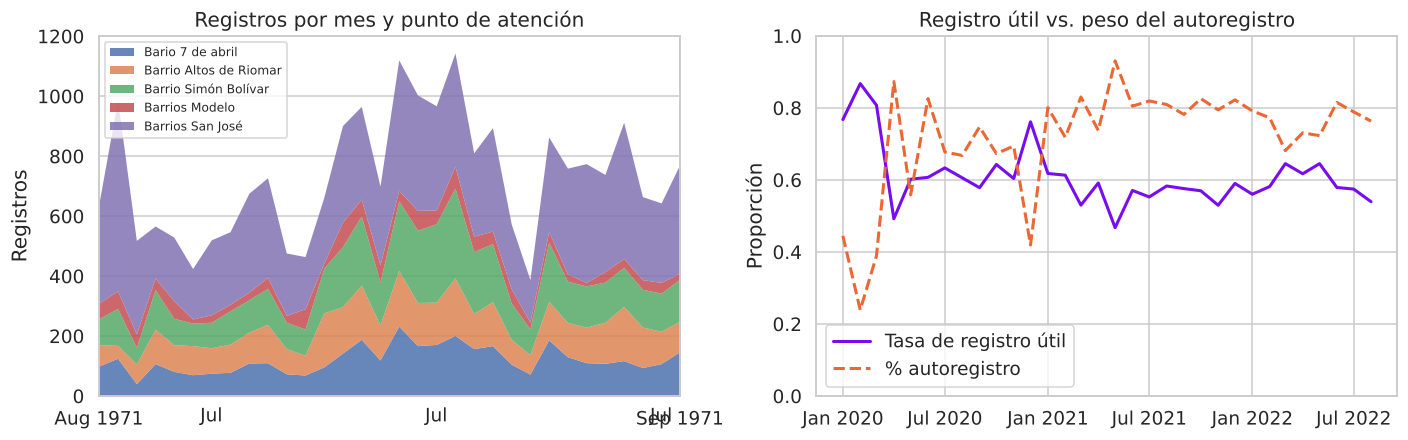

Mes pico: 2021-08 con 1,144 registros. Promedio mensual: 730.
Correlación mensual entre % autoregistro y tasa útil: -0.94


In [6]:
mensual = df.groupby("periodo").agg(
    registros=("canal", "size"),
    tasa_util=("registro_util", "mean"),
    pct_auto=("canal", lambda s: (s == "Autoregistro").mean()),
)
por_punto_mes = df.groupby(["periodo", "punto"]).size().unstack()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
por_punto_mes.plot.area(ax=axes[0], alpha=0.85, linewidth=0)
axes[0].set(title="Registros por mes y punto de atención", xlabel="", ylabel="Registros")
axes[0].legend(title=None, fontsize=8, loc="upper left")

axes[1].plot(mensual.index, mensual["tasa_util"], color=MORADO, linewidth=2, label="Tasa de registro útil")
axes[1].plot(mensual.index, mensual["pct_auto"], color=NARANJA, linewidth=2, linestyle="--", label="% autoregistro")
axes[1].set(title="Registro útil vs. peso del autoregistro", xlabel="", ylabel="Proporción", ylim=(0, 1))
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
guardar("fig01_evolucion_mensual")
plt.show()

pico = mensual["registros"].idxmax()
print(f"Mes pico: {pico:%Y-%m} con {mensual['registros'].max():,} registros. Promedio mensual: {mensual['registros'].mean():,.0f}.")
print(f"Correlación mensual entre % autoregistro y tasa útil: {mensual['pct_auto'].corr(mensual['tasa_util']):.2f}")

## 3.2 Canal y punto de atención

El gráfico muestra la tasa de registro útil por **punto** y **canal**. La línea punteada es la tasa global.

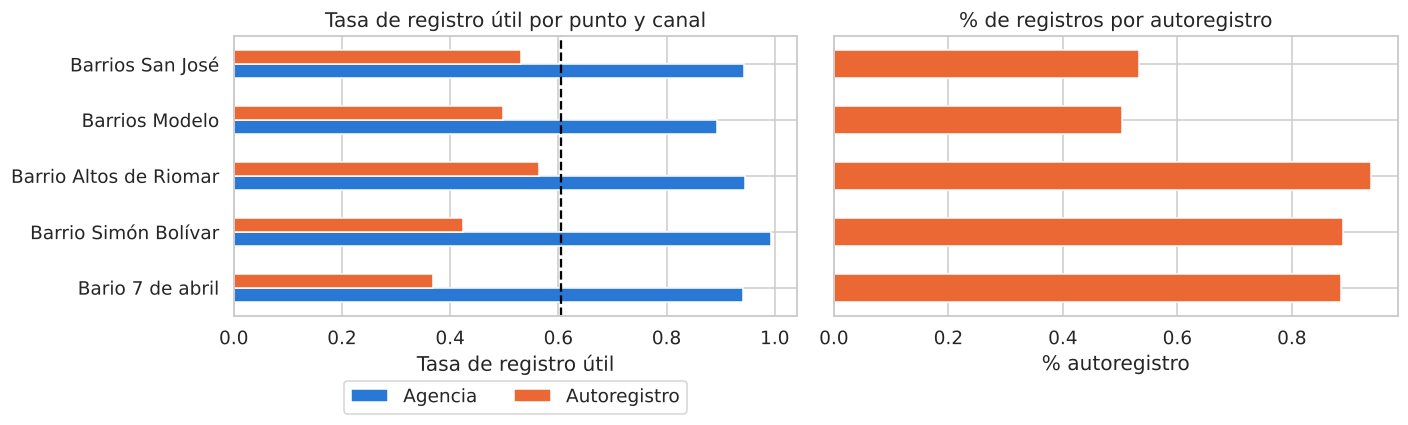

Prueba χ² canal vs registro útil: χ² = 4,196, p = 0.00e+00, V de Cramér = 0.42


,tasa_util,registros
canal,,
Agencia,0.942,6395
Autoregistro,0.478,16958


In [7]:
tasa_canal_punto = df.pivot_table(index="punto", columns="canal", values="registro_util", aggfunc="mean")
n_canal_punto = df.pivot_table(index="punto", columns="canal", values="registro_util", aggfunc="size")
orden_puntos = df.groupby("punto")["registro_util"].mean().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
tasa_canal_punto.loc[orden_puntos].plot.barh(ax=axes[0], color={"Agencia": AZUL, "Autoregistro": NARANJA})
axes[0].axvline(util_global, color="black", linestyle="--")
axes[0].set(title="Tasa de registro útil por punto y canal", xlabel="Tasa de registro útil", ylabel="")
axes[0].legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

pct_auto_punto = (n_canal_punto["Autoregistro"] / n_canal_punto.sum(axis=1)).loc[orden_puntos]
pct_auto_punto.plot.barh(ax=axes[1], color=NARANJA)
axes[1].set(title="% de registros por autoregistro", xlabel="% autoregistro", ylabel="")
plt.tight_layout()
guardar("fig02_canal_punto")
plt.show()

tabla_canal = df.groupby("canal")["registro_util"].agg(["mean", "size"]).rename(columns={"mean": "tasa_util", "size": "registros"})
display_tabla = tabla_canal.copy()
chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(df["canal"], df["registro_util"]))
v_cramer = np.sqrt(chi2 / len(df))
print(f"Prueba χ² canal vs registro útil: χ² = {chi2:,.0f}, p = {p_chi:.2e}, V de Cramér = {v_cramer:.2f}")
tabla_canal

## 3.3 Horario de registro

Se cruza el **día de la semana** con la **franja horaria** (hora en que se hizo el registro).

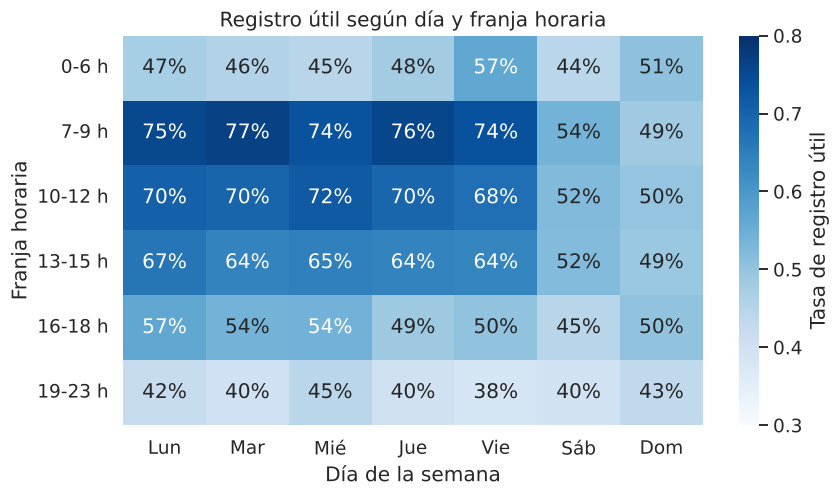

Mejor franja: 7-9 h (73%); peor franja: 19-23 h (41%).
Entre semana: 62% · fin de semana: 48%


In [8]:
nombres_dias = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
d_hora = df.dropna(subset=["franja"]).copy()
d_hora["dia"] = d_hora["dia_semana"].map(nombres_dias)
mapa = d_hora.pivot_table(index="franja", columns="dia", values="registro_util", aggfunc="mean", observed=True)
mapa = mapa[list(nombres_dias.values())]

plt.figure(figsize=(8.5, 4.6))
sns.heatmap(mapa, annot=True, fmt=".0%", cmap="Blues", vmin=0.3, vmax=0.8, cbar_kws={"label": "Tasa de registro útil"})
plt.title("Registro útil según día y franja horaria")
plt.xlabel("Día de la semana")
plt.ylabel("Franja horaria")
guardar("fig03_horario")
plt.show()

tasa_franja = d_hora.groupby("franja", observed=True)["registro_util"].mean()
tasa_semana = d_hora.assign(finde=d_hora["dia_semana"] >= 5).groupby("finde")["registro_util"].mean()
print(f"Mejor franja: {tasa_franja.idxmax()} ({tasa_franja.max():.0%}); peor franja: {tasa_franja.idxmin()} ({tasa_franja.min():.0%}).")
print(f"Entre semana: {tasa_semana[False]:.0%} · fin de semana: {tasa_semana[True]:.0%}")

## 3.4 ¿Quiénes se registran?

Perfil de la población que sí informó su situación laboral. La población prioritaria son los desempleados, quienes buscan primer empleo y los cesantes por la emergencia sanitaria.

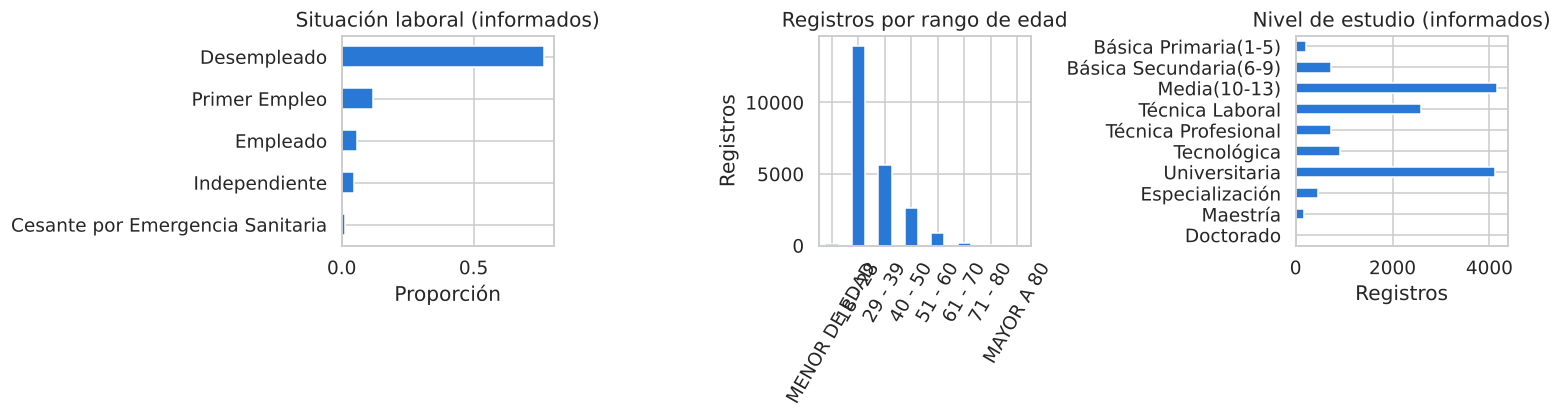

Población prioritaria entre quienes informaron situación laboral: 89.7%
Mujeres: 55.5% · 18 a 28 años: 59.8% · Barranquilla: 86.7%


In [9]:
informados = df[df["sit_informada"] == 1].copy()
informados["prioritario"] = informados["sit_laboral"].isin(["Desempleado", "Primer Empleo", "Cesante por Emergencia Sanitaria"]).astype(int)
pct_prioritario = informados["prioritario"].mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
(informados["sit_laboral"].value_counts(normalize=True).sort_values().plot.barh(ax=axes[0], color=AZUL))
axes[0].set(title="Situación laboral (informados)", xlabel="Proporción", ylabel="")

df.groupby("rango_edad").size().reindex(
    ["MENOR DE EDAD", "18 - 28", "29 - 39", "40 - 50", "51 - 60", "61 - 70", "71 - 80", "MAYOR A 80"]
).plot.bar(ax=axes[1], color=AZUL)
axes[1].set(title="Registros por rango de edad", xlabel="", ylabel="Registros")
axes[1].tick_params(axis="x", rotation=60)

niv = informados[informados["nivel_ord"].notna()]["nivel_estudio"].value_counts()
niv.reindex([k for k in orden_nivel if k in niv.index]).plot.barh(ax=axes[2], color=AZUL)
axes[2].set(title="Nivel de estudio (informados)", xlabel="Registros", ylabel="")
axes[2].invert_yaxis()
plt.tight_layout()
guardar("fig04_perfil")
plt.show()

print(f"Población prioritaria entre quienes informaron situación laboral: {pct_prioritario:.1%}")
print(f"Mujeres: {(df['genero'] == 'F').mean():.1%} · 18 a 28 años: {(df['rango_edad'] == '18 - 28').mean():.1%} · Barranquilla: {(df['ciudad_g'] == 'Barranquilla').mean():.1%}")

## 3.5 Concentración: ¿dónde está el problema?

Un análisis tipo Pareto por punto muestra cuánto del volumen y cuántos de los registros incompletos concentra cada uno. Esto orienta dónde intervenir primero.

In [10]:
pareto = df.groupby("punto").agg(
    registros=("canal", "size"),
    incompletos=("incompleto", "sum"),
    tasa_util=("registro_util", "mean"),
    pct_auto=("canal", lambda s: (s == "Autoregistro").mean()),
)
pareto["pct_registros"] = pareto["registros"] / pareto["registros"].sum() * 100
pareto["pct_incompletos"] = pareto["incompletos"] / pareto["incompletos"].sum() * 100
pareto = pareto.sort_values("incompletos", ascending=False)
pareto["pct_incompletos_acum"] = pareto["pct_incompletos"].cumsum()
pareto

,registros,incompletos,tasa_util,pct_auto,pct_registros,pct_incompletos,pct_incompletos_acum
punto,,,,,,,
Barrios San José,9757,2696,0.724,0.533,41.780,29.222,29.222
Barrio Simón Bolívar,4652,2385,0.487,0.889,19.920,25.851,55.073
Bario 7 de abril,3884,2199,0.434,0.886,16.632,23.835,78.907
Barrio Altos de Riomar,3774,1553,0.589,0.938,16.161,16.833,95.740
Barrios Modelo,1286,393,0.694,0.503,5.507,4.260,100.000


# 4 Modelo 1: regresión

Se usan dos regresiones lineales, ambas estimadas por mínimos cuadrados (función `ols()` definida abajo, equivalente a `smf.ols().fit()` de statsmodels):

1. **Relación entre canal y calidad (decisión):** a nivel de punto × mes, ¿cuánto cambia la tasa de registro útil por cada punto porcentual de autoregistro?
2. **Pronóstico de demanda (capacidad):** modelo log-lineal de los registros mensuales con tendencia y estacionalidad.

## 4.1 Efecto del autoregistro sobre la tasa de registro útil

$$\text{tasa\_util}_{p,t} = \beta_0 + \beta_1\,\text{pct\_auto}_{p,t} + \beta_2\,t + \gamma_p + \varepsilon$$

donde $\gamma_p$ son efectos fijos de punto y $t$ la tendencia mensual. Solo se usan celdas punto-mes con al menos 30 registros, para que las tasas sean estables.

In [11]:
def ols(X, y, nombres):
    # Mínimos cuadrados ordinarios: devuelve tabla de coeficientes, R², coeficientes y residuos
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, k = X.shape
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    residuos = y - X @ beta
    sigma2 = residuos @ residuos / (n - k)
    error = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
    t = beta / error
    p = 2 * stats.t.sf(np.abs(t), n - k)
    t_crit = stats.t.ppf(0.975, n - k)
    r2 = 1 - residuos @ residuos / ((y - y.mean()) @ (y - y.mean()))
    tabla = pd.DataFrame({
        "coef": beta, "error_est": error, "t": t, "p_valor": p,
        "ic_inf": beta - t_crit * error, "ic_sup": beta + t_crit * error,
    }, index=nombres)
    return tabla, r2, beta, residuos


panel = df.groupby(["periodo", "punto"]).agg(
    registros=("canal", "size"),
    tasa_util=("registro_util", "mean"),
    pct_auto=("canal", lambda s: (s == "Autoregistro").mean()),
).reset_index()
panel["t"] = (panel["periodo"].dt.year - 2020) * 12 + panel["periodo"].dt.month
panel = panel[panel["registros"] >= 30].copy()

X_panel = pd.get_dummies(panel[["pct_auto", "t", "punto"]], columns=["punto"], drop_first=True, dtype=int)
X_panel.insert(0, "const", 1.0)
tabla_reg, r2_reg, _, _ = ols(X_panel, panel["tasa_util"], X_panel.columns)
print(f"Observaciones punto-mes: {len(panel)} · R² = {r2_reg:.3f}")
tabla_reg

Observaciones punto-mes: 150 · R² = 0.813


,coef,error_est,t,p_valor,ic_inf,ic_sup
const,8.812e-01,3.291e-02,26.777,1.418e-57,0.816,0.946
pct_auto,-4.961e-01,4.023e-02,-12.332,2.948e-24,-0.576,-0.417
t,-6.493e-05,6.550e-04,-0.099,9.212e-01,-0.001,0.001
punto_Barrio Altos de Riomar,1.716e-01,1.621e-02,10.584,1.082e-19,0.140,0.204
punto_Barrio Simón Bolívar,5.104e-02,1.608e-02,3.175,1.837e-03,0.019,0.083
punto_Barrios Modelo,5.900e-02,2.377e-02,2.482,1.421e-02,0.012,0.106
punto_Barrios San José,1.046e-01,2.067e-02,5.062,1.256e-06,0.064,0.145


Por cada +10 puntos porcentuales de autoregistro, la tasa de registro útil cambia -5.0 puntos (IC 95 %: -5.8 a -4.2; p = 2.9e-24).


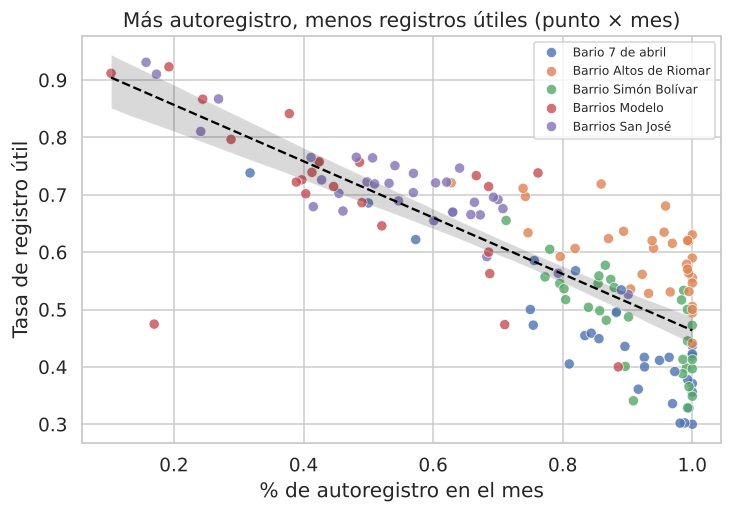

In [12]:
beta_auto = tabla_reg.loc["pct_auto", "coef"]
ic_auto = tabla_reg.loc[["pct_auto"], ["ic_inf", "ic_sup"]].values[0]
print(f"Por cada +10 puntos porcentuales de autoregistro, la tasa de registro útil cambia {beta_auto * 10:+.1f} puntos "
      f"(IC 95 %: {ic_auto[0] * 10:+.1f} a {ic_auto[1] * 10:+.1f}; p = {tabla_reg.loc['pct_auto', 'p_valor']:.1e}).")

plt.figure(figsize=(7.5, 4.8))
sns.scatterplot(data=panel, x="pct_auto", y="tasa_util", hue="punto", s=45, alpha=0.8)
xs = np.linspace(panel["pct_auto"].min(), panel["pct_auto"].max(), 50)
sns.regplot(data=panel, x="pct_auto", y="tasa_util", scatter=False, color="black", line_kws={"linewidth": 1.5, "linestyle": "--"})
plt.title("Más autoregistro, menos registros útiles (punto × mes)")
plt.xlabel("% de autoregistro en el mes")
plt.ylabel("Tasa de registro útil")
plt.legend(title=None, fontsize=8)
guardar("fig05_regresion_canal")
plt.show()

## 4.2 Pronóstico de la demanda de registros

Con 32 meses y 5 puntos se comparan tres modelos log-lineales de los registros mensuales y una línea base sencilla (promedio de los últimos 3 meses de cada punto):

$$\ln(\text{registros}_{p,t}) = \beta_0 + \beta_1\,t + \sum_m \delta_m\,\text{mes}_m + \gamma_p + \varepsilon$$

(las variantes quitan la tendencia $t$ o la estacionalidad por mes). Se valida con los últimos 6 meses (marzo a agosto de 2022), que el modelo no ve al entrenar, usando el **MAPE** (error porcentual absoluto medio). Se elige el de menor error y se reestima con todos los datos para proyectar los 4 meses siguientes (sep a dic de 2022).

In [13]:
demanda = df.groupby(["periodo", "punto"]).size().rename("registros").reset_index()
demanda["t"] = (demanda["periodo"].dt.year - 2020) * 12 + demanda["periodo"].dt.month
demanda["mes"] = demanda["periodo"].dt.month
PUNTOS = sorted(df["punto"].unique())


def matriz_demanda(tabla, tendencia=True, estacionalidad=True):
    # Columnas fijas (todas las categorías) para que entrenamiento, prueba y futuro sean comparables
    X = pd.DataFrame({"const": 1.0}, index=tabla.index)
    if tendencia:
        X["t"] = tabla["t"]
    if estacionalidad:
        for m in range(2, 13):
            X[f"mes_{m}"] = (tabla["mes"] == m).astype(int)
    for p in PUNTOS[1:]:
        X[f"punto_{p}"] = (tabla["punto"] == p).astype(int)
    return X


def evaluar(tabla, pronostico):
    # MAPE del total mensual y MAPE por punto-mes
    g = tabla.assign(pron=pronostico).groupby("periodo")[["registros", "pron"]].sum()
    return ((g["registros"] - g["pron"]).abs() / g["registros"]).mean(), ((tabla["registros"] - pronostico).abs() / tabla["registros"]).mean()


corte = pd.Timestamp("2022-02-01")
entr_d = demanda[demanda["periodo"] <= corte]
prueba_d = demanda[demanda["periodo"] > corte].copy()

candidatos = {
    "Tendencia + estacionalidad": dict(tendencia=True, estacionalidad=True),
    "Solo tendencia": dict(tendencia=True, estacionalidad=False),
    "Solo estacionalidad": dict(tendencia=False, estacionalidad=True),
}
filas_c, pronosticos = [], {}
for nombre, opciones in candidatos.items():
    X_e = matriz_demanda(entr_d, **opciones)
    _, _, b, _ = ols(X_e, np.log(entr_d["registros"]), X_e.columns)
    pron = np.exp(matriz_demanda(prueba_d, **opciones).values @ b)
    pronosticos[nombre] = pron
    m_tot, m_pt = evaluar(prueba_d, pron)
    filas_c.append({"modelo": nombre, "MAPE total mensual": m_tot, "MAPE punto-mes": m_pt})

# Línea base: promedio de los últimos 3 meses de entrenamiento por punto
base3 = entr_d[entr_d["periodo"] > corte - pd.DateOffset(months=3)].groupby("punto")["registros"].mean()
pron_base = prueba_d["punto"].map(base3).to_numpy()
m_tot, m_pt = evaluar(prueba_d, pron_base)
filas_c.append({"modelo": "Línea base: promedio últimos 3 meses", "MAPE total mensual": m_tot, "MAPE punto-mes": m_pt})
comparacion_demanda = pd.DataFrame(filas_c).set_index("modelo")

mejor_demanda = comparacion_demanda.iloc[:3]["MAPE total mensual"].idxmin()
mape_total = comparacion_demanda.loc[mejor_demanda, "MAPE total mensual"]
mape_punto = comparacion_demanda.loc[mejor_demanda, "MAPE punto-mes"]
prueba_d["pronostico"] = pronosticos[mejor_demanda]
print(f"Modelo elegido: {mejor_demanda} (MAPE total mensual {mape_total:.1%}; por punto-mes {mape_punto:.1%})")
comparacion_demanda

Modelo elegido: Solo estacionalidad (MAPE total mensual 8.2%; por punto-mes 24.1%)


,MAPE total mensual,MAPE punto-mes
modelo,,
Tendencia + estacionalidad,0.453,0.720
Solo tendencia,0.228,0.473
Solo estacionalidad,0.082,0.241
Línea base: promedio últimos 3 meses,0.112,0.206


In [14]:
# Reestimar el modelo elegido con todos los datos y proyectar sep-dic 2022
opciones = candidatos[mejor_demanda]
X_d = matriz_demanda(demanda, **opciones)
tabla_d, r2_d, beta_dall, _ = ols(X_d, np.log(demanda["registros"]), X_d.columns)

futuro = pd.DataFrame([(pd.Timestamp(2022, m, 1), p) for m in range(9, 13) for p in PUNTOS], columns=["periodo", "punto"])
futuro["t"] = (futuro["periodo"].dt.year - 2020) * 12 + futuro["periodo"].dt.month
futuro["mes"] = futuro["periodo"].dt.month
futuro["pronostico"] = np.exp(matriz_demanda(futuro, **opciones).values @ beta_dall)

print(f"R² del modelo de demanda (con todos los datos): {r2_d:.3f}")
efectos_mes = np.exp(tabla_d.filter(like="mes_", axis=0)["coef"]) - 1
print("Meses más fuertes frente a enero:", efectos_mes.sort_values(ascending=False).head(3).round(2).to_dict())
proy = futuro.groupby("periodo")["pronostico"].sum().round(0)
print("Proyección total sep-dic 2022:", {f"{k:%Y-%m}": int(v) for k, v in proy.items()})

R² del modelo de demanda (con todos los datos): 0.780
Meses más fuertes frente a enero: {'mes_10': 0.17, 'mes_2': 0.16, 'mes_5': 0.15}
Proyección total sep-dic 2022: {'2022-09': 724, '2022-10': 798, '2022-11': 540, '2022-12': 462}


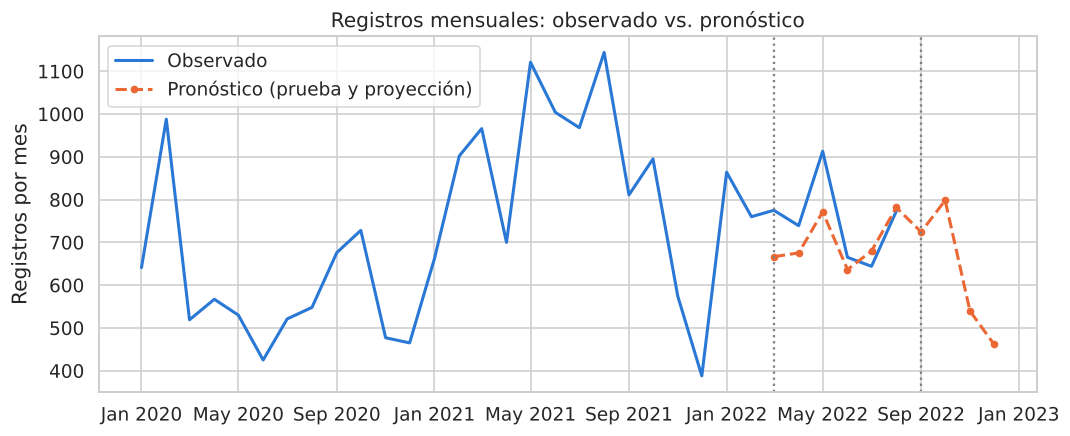

In [15]:
real_total = demanda.groupby("periodo")["registros"].sum()
pron_total = pd.concat([
    prueba_d.groupby("periodo")["pronostico"].sum(),
    futuro.groupby("periodo")["pronostico"].sum(),
])

plt.figure(figsize=(11, 4.2))
plt.plot(real_total.index, real_total.values, color=AZUL, linewidth=2, label="Observado")
plt.plot(pron_total.index, pron_total.values, color=NARANJA, linewidth=2, linestyle="--", marker="o", markersize=4, label="Pronóstico (prueba y proyección)")
plt.axvline(corte + pd.offsets.MonthBegin(1), color="gray", linestyle=":")
plt.axvline(pd.Timestamp("2022-09-01"), color="gray", linestyle=":")
plt.title("Registros mensuales: observado vs. pronóstico")
plt.ylabel("Registros por mes")
plt.legend()
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
guardar("fig06_pronostico")
plt.show()

# 5 Modelo 2: clasificación

**Objetivo:** estimar la probabilidad de que un registro quede **incompleto** (`incompleto = 1`) usando solo lo que se conoce **al momento del registro**: edad, género, documento, canal, punto, ciudad, franja horaria, día y año. Las variables que definen el resultado (situación laboral, nivel de estudio, zona) **no** se usan como predictores, para no filtrar la respuesta.

Se comparan cuatro modelos, igual que en el notebook de referencia: logit, árbol de clasificación, random forest y boosting (XGBoost si está instalado; si no, `HistGradientBoostingClassifier` de scikit-learn).

## 5.1 Predictores y partición 70/30

In [16]:
modelo_df = df.dropna(subset=["fecha_registro"]).copy()  # 11 registros sin fecha válida no entran al modelo
modelo_df["edad_decada"] = modelo_df["edad"] / 10
modelo_df["es_mujer"] = (modelo_df["genero"] == "F").astype(int)
modelo_df["autoregistro"] = (modelo_df["canal"] == "Autoregistro").astype(int)
modelo_df["fin_semana"] = (modelo_df["dia_semana"] >= 5).astype(int)
modelo_df["doc_cedula"] = (modelo_df["tipo_doc"] == "Cédula de Ciudadanía").astype(int)
modelo_df["anio_cat"] = modelo_df["anio"].astype(str)
modelo_df["franja"] = modelo_df["franja"].astype(str)

predictores = ["edad_decada", "es_mujer", "autoregistro", "fin_semana", "doc_cedula", "punto", "ciudad_g", "franja", "anio_cat"]

# Se crean las variables indicadoras con TODOS los datos para que entrenamiento y prueba tengan las mismas columnas
X_total = pd.get_dummies(modelo_df[predictores], drop_first=True, dtype=int)
y_total = modelo_df["incompleto"]

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X_total, y_total, test_size=0.3, stratify=y_total, random_state=SEMILLA
)
pd.DataFrame({
    "registros": [len(X_entrenamiento), len(X_prueba)],
    "tasa_incompleto": [y_entrenamiento.mean(), y_prueba.mean()],
}, index=["Entrenamiento", "Prueba"])

,registros,tasa_incompleto
Entrenamiento,16339,0.395
Prueba,7003,0.395


## 5.2 Regresión logística

Se estima por máxima verosimilitud (sin penalización) y se calculan errores estándar con la matriz de información, de modo que los **odds ratios** y sus intervalos coinciden con los de `smf.logit()`.

In [17]:
def logit_ajuste(X, y):
    # Logit sin penalización + errores estándar de Wald (equivale a smf.logit)
    modelo = LogisticRegression(C=np.inf, max_iter=5000)  # C infinito = sin penalización
    modelo.fit(X, y)
    X1 = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    beta = np.r_[modelo.intercept_, modelo.coef_.ravel()]
    p = modelo.predict_proba(X)[:, 1]
    cov = np.linalg.inv((X1 * (p * (1 - p))[:, None]).T @ X1)
    error = np.sqrt(np.diag(cov))
    z = beta / error
    tabla = pd.DataFrame({
        "odds_ratio": np.exp(beta),
        "conf_low": np.exp(beta - 1.96 * error),
        "conf_high": np.exp(beta + 1.96 * error),
        "p_valor": 2 * stats.norm.sf(np.abs(z)),
    }, index=["Intercepto"] + list(X.columns))
    return modelo, tabla


logit, odds_ratios = logit_ajuste(X_entrenamiento, y_entrenamiento)
odds_ratios.sort_values("odds_ratio", ascending=False)

,odds_ratio,conf_low,conf_high,p_valor
autoregistro,14.546,12.666,16.704,0.000e+00
franja_19-23 h,1.477,1.202,1.816,2.131e-04
ciudad_g_Otro municipio,1.270,1.089,1.482,2.311e-03
es_mujer,1.177,1.096,1.264,6.726e-06
edad_decada,1.110,1.069,1.152,4.910e-08
franja_16-18 h,1.104,0.898,1.358,3.465e-01
fin_semana,1.092,0.981,1.217,1.085e-01
anio_cat_2021,1.038,0.951,1.132,4.053e-01
anio_cat_2022,1.026,0.931,1.131,6.024e-01
ciudad_g_Soledad,0.935,0.828,1.055,2.734e-01


In [18]:
or_auto = odds_ratios.loc["autoregistro", "odds_ratio"]
or_fin = odds_ratios.loc["fin_semana", "odds_ratio"]
print(f"Autoregistrarse multiplica los odds de registro incompleto por {or_auto:.1f} frente a hacerlo con un orientador (ajustado por las demás variables).")
print(f"Registrarse en fin de semana los multiplica por {or_fin:.2f}.")

# Contraste opcional con statsmodels
if HAY_SM:
    import statsmodels.api as sm
    sm_logit = sm.Logit(y_entrenamiento, sm.add_constant(X_entrenamiento.astype(float))).fit(disp=False)
    print("\nstatsmodels - odds ratio de autoregistro:", round(float(np.exp(sm_logit.params["autoregistro"])), 3))
else:
    print("\n(statsmodels no está instalado: se usó la implementación propia, que da los mismos coeficientes.)")

Autoregistrarse multiplica los odds de registro incompleto por 14.5 frente a hacerlo con un orientador (ajustado por las demás variables).
Registrarse en fin de semana los multiplica por 1.09.

(statsmodels no está instalado: se usó la implementación propia, que da los mismos coeficientes.)


## 5.3 Árbol, random forest y boosting

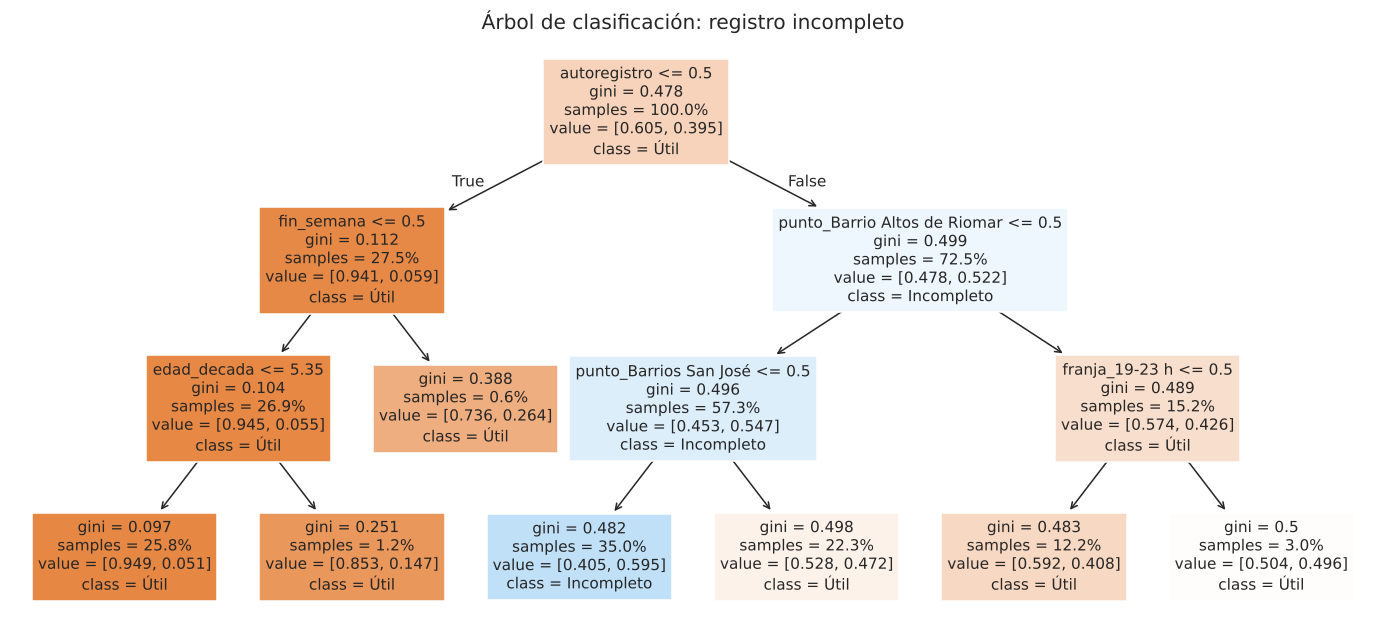

|--- autoregistro <= 0.50
|   |--- fin_semana <= 0.50
|   |   |--- edad_decada <= 5.35
|   |   |   |--- weights: [3995.00, 215.00] class: 0
|   |   |--- edad_decada >  5.35
|   |   |   |--- weights: [162.00, 28.00] class: 0
|   |--- fin_semana >  0.50
|   |   |--- weights: [67.00, 24.00] class: 0
|--- autoregistro >  0.50
|   |--- punto_Barrio Altos de Riomar <= 0.50
|   |   |--- punto_Barrios San José <= 0.50
|   |   |   |--- weights: [2316.00, 3404.00] class: 1
|   |   |--- punto_Barrios San José >  0.50
|   |   |   |--- weights: [1925.00, 1724.00] class: 0
|   |--- punto_Barrio Altos de Riomar >  0.50
|   |   |--- franja_19-23 h <= 0.50
|   |   |   |--- weights: [1177.00, 812.00] class: 0
|   |   |--- franja_19-23 h >  0.50
|   |   |   |--- weights: [247.00, 243.00] class: 0



In [19]:
arbol = DecisionTreeClassifier(max_depth=3, min_samples_split=150, min_samples_leaf=50, random_state=SEMILLA)
arbol.fit(X_entrenamiento, y_entrenamiento)

plt.figure(figsize=(16, 7))
plot_tree(arbol, feature_names=X_entrenamiento.columns, class_names=["Útil", "Incompleto"], filled=True, proportion=True, fontsize=10)
plt.title("Árbol de clasificación: registro incompleto")
guardar("fig07_arbol")
plt.show()

print(export_text(arbol, feature_names=list(X_entrenamiento.columns), show_weights=True))

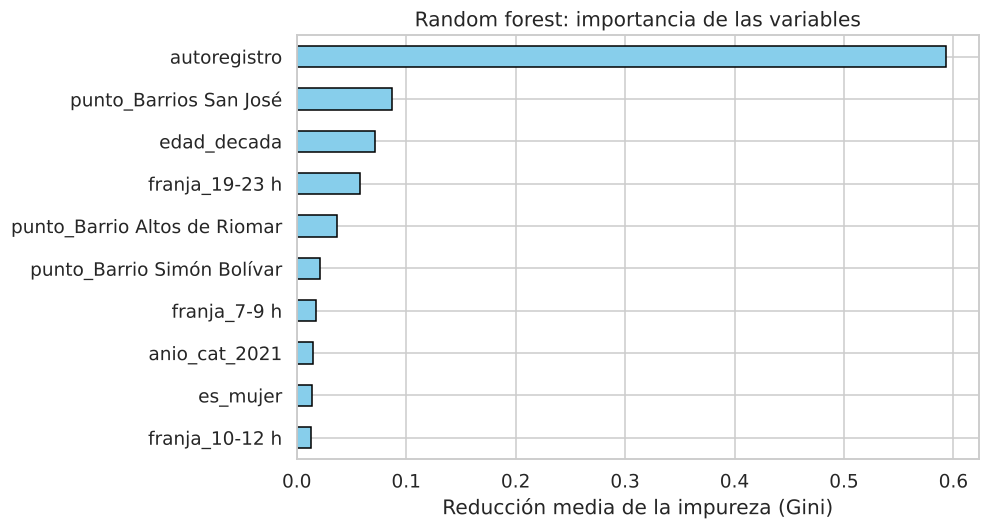

Boosting usado: Boosting (sklearn)


In [20]:
bosque = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=SEMILLA, n_jobs=-1)
bosque.fit(X_entrenamiento, y_entrenamiento)

if HAY_XGB:
    nombre_boost = "XGBoost"
    boost = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, min_child_weight=20, random_state=SEMILLA)
else:
    nombre_boost = "Boosting (sklearn)"
    boost = HistGradientBoostingClassifier(max_iter=300, max_depth=3, learning_rate=0.05, min_samples_leaf=20, random_state=SEMILLA)
boost.fit(X_entrenamiento, y_entrenamiento)

importancia = pd.Series(bosque.feature_importances_, index=X_entrenamiento.columns).sort_values()
plt.figure(figsize=(8, 5))
importancia.tail(10).plot.barh(color="skyblue", edgecolor="black")
plt.title("Random forest: importancia de las variables")
plt.xlabel("Reducción media de la impureza (Gini)")
guardar("fig08_importancia")
plt.show()
print(f"Boosting usado: {nombre_boost}")

## 5.4 Comparación de modelos

Cada modelo entrega la probabilidad de que el registro quede incompleto en la **muestra de prueba**; se predice "incompleto" con umbral 0,5.

In [21]:
probabilidades = {
    "Logit": logit.predict_proba(X_prueba)[:, 1],
    "Árbol": arbol.predict_proba(X_prueba)[:, 1],
    "Random forest": bosque.predict_proba(X_prueba)[:, 1],
    nombre_boost: boost.predict_proba(X_prueba)[:, 1],
}

filas = []
for nombre, prob in probabilidades.items():
    clase = (prob >= 0.5).astype(int)
    filas.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_prueba, clase),
        "precisión": precision_score(y_prueba, clase),
        "sensibilidad": recall_score(y_prueba, clase),
        "especificidad": recall_score(y_prueba, clase, pos_label=0),
        "F1": f1_score(y_prueba, clase),
        "AUC": roc_auc_score(y_prueba, prob),
    })
metricas = pd.DataFrame(filas).set_index("modelo")
metricas

,exactitud,precisión,sensibilidad,especificidad,F1,AUC
modelo,,,,,,
Logit,0.675,0.584,0.615,0.714,0.599,0.751
Árbol,0.668,0.589,0.531,0.758,0.558,0.733
Random forest,0.673,0.584,0.593,0.724,0.589,0.751
Boosting (sklearn),0.676,0.583,0.629,0.706,0.605,0.751


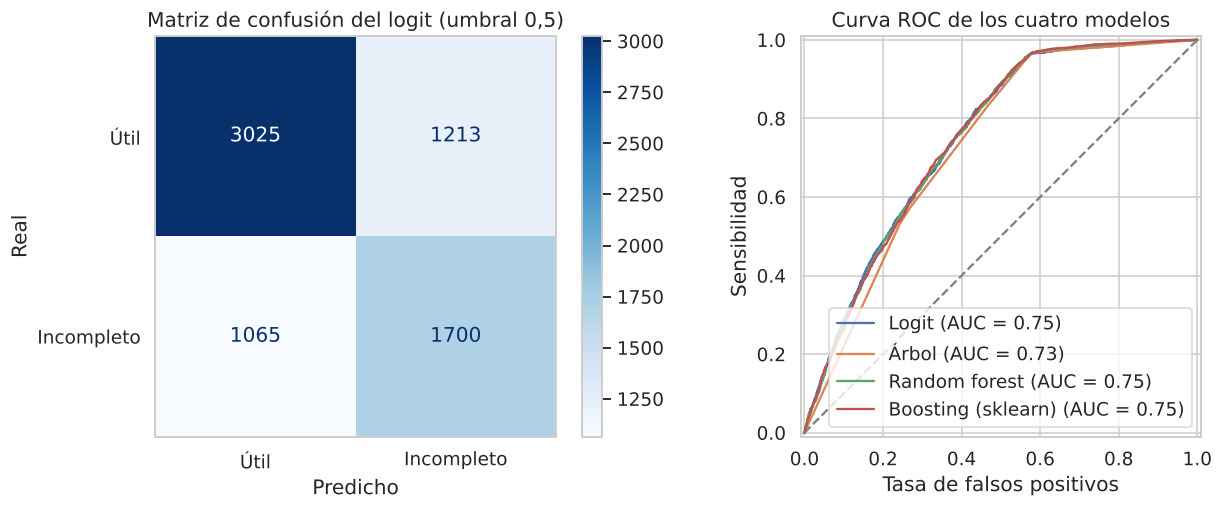

Mejor AUC: Boosting (sklearn) (0.751). AUC del logit: 0.751.


In [22]:
prob_logit = probabilidades["Logit"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_prueba, (prob_logit >= 0.5).astype(int), display_labels=["Útil", "Incompleto"], cmap="Blues", ax=axes[0]
)
axes[0].set(title="Matriz de confusión del logit (umbral 0,5)", xlabel="Predicho", ylabel="Real")
axes[0].grid(False)

for nombre, prob in probabilidades.items():
    RocCurveDisplay.from_predictions(y_prueba, prob, name=nombre, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[1].set(title="Curva ROC de los cuatro modelos", xlabel="Tasa de falsos positivos", ylabel="Sensibilidad")
plt.tight_layout()
guardar("fig09_roc_confusion")
plt.show()

mejor = metricas["AUC"].idxmax()
print(f"Mejor AUC: {mejor} ({metricas['AUC'].max():.3f}). AUC del logit: {metricas.loc['Logit', 'AUC']:.3f}.")

# 6 Modelo 3: segmentación (k-means)

Se agrupa a las personas con **registro útil** (n ≈ 14 mil) para diseñar acciones distintas según su perfil. Variables: edad, nivel de estudio (escala 1 a 10), y dos indicadores de situación laboral (primer empleo y ocupado). Se estandarizan antes de calcular distancias. Género y punto no entran al agrupamiento; se usan para **perfilar** cada segmento.

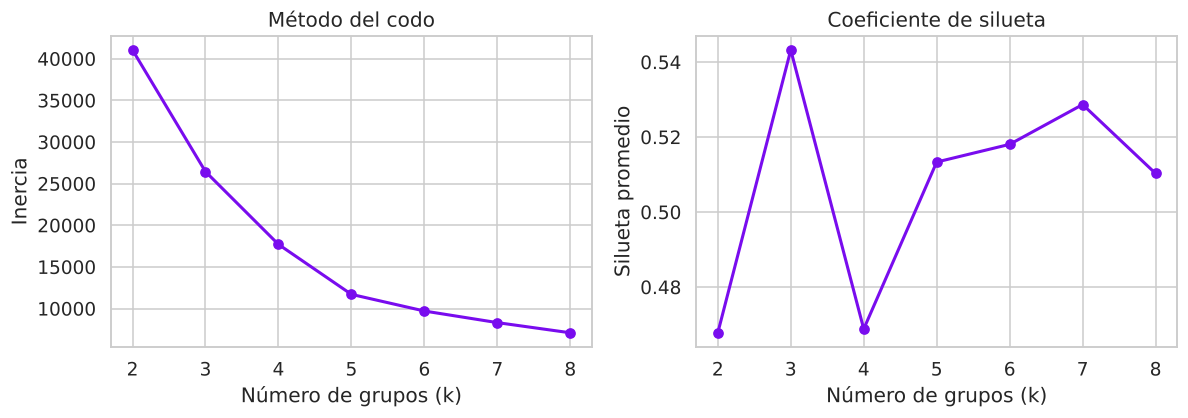

,k,inercia,silueta
0,2,41043.418,0.468
1,3,26439.519,0.543
2,4,17702.579,0.469
3,5,11701.696,0.513
4,6,9700.531,0.518
5,7,8308.637,0.529
6,8,7086.534,0.510


In [23]:
perfiles = df[df["registro_util"] == 1].copy()
perfiles["primer_empleo"] = (perfiles["sit_laboral"] == "Primer Empleo").astype(int)
perfiles["ocupado"] = perfiles["sit_laboral"].isin(["Empleado", "Independiente"]).astype(int)
perfiles["mujer"] = (perfiles["genero"] == "F").astype(int)

variables_seg = ["edad", "nivel_ord", "primer_empleo", "ocupado"]
escalador = StandardScaler()
X_seg = escalador.fit_transform(perfiles[variables_seg])

k_valores = range(2, 9)
inercia, silueta = [], []
for k in k_valores:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X_seg)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X_seg, km.labels_, sample_size=5000, random_state=SEMILLA))
seleccion_k = pd.DataFrame({"k": list(k_valores), "inercia": inercia, "silueta": silueta})

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(seleccion_k["k"], seleccion_k["inercia"], marker="o", color=MORADO, linewidth=2)
axes[0].set(title="Método del codo", xlabel="Número de grupos (k)", ylabel="Inercia")
axes[1].plot(seleccion_k["k"], seleccion_k["silueta"], marker="o", color=MORADO, linewidth=2)
axes[1].set(title="Coeficiente de silueta", xlabel="Número de grupos (k)", ylabel="Silueta promedio")
plt.tight_layout()
guardar("fig10_codo_silueta")
plt.show()
seleccion_k

La silueta más alta ocurre con pocos grupos, pero con $k=3$ se mezclan perfiles que requieren acciones distintas (por ejemplo, desempleados jóvenes con desempleados mayores). Se elige $k = 5$ porque conserva una silueta alta (por encima de 0,5), está en la zona del codo y produce segmentos **accionables**. Es una decisión de negocio, no solo estadística.

In [24]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X_seg)
perfiles["grupo"] = kmeans.labels_

perfil = perfiles.groupby("grupo").agg(
    clientes=("edad", "size"),
    edad=("edad", "mean"),
    nivel=("nivel_ord", "mean"),
    pct_primer_empleo=("primer_empleo", "mean"),
    pct_ocupado=("ocupado", "mean"),
    pct_mujer=("mujer", "mean"),
    pct_auto=("canal", lambda s: (s == "Autoregistro").mean()),
)
perfil["pct_clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil = perfil.sort_values("edad")
perfil

,clientes,edad,nivel,pct_primer_empleo,pct_ocupado,pct_mujer,pct_auto,pct_clientes
grupo,,,,,,,,
3,1698,22.058,5.108,1.0,0.000e+00,0.548,0.770,12.020
1,5050,25.012,3.390,0.0,0.000e+00,0.531,0.439,35.747
2,3676,27.813,6.902,0.0,0.000e+00,0.566,0.700,26.021
0,1428,32.283,5.991,0.0,1.000e+00,0.511,0.821,10.108
4,2275,45.440,3.608,0.0,4.396e-04,0.556,0.365,16.104


In [25]:
# Nombrar los segmentos a partir de su perfil (se ordenan por edad promedio, de menor a mayor)
def nombrar(fila):
    if fila["pct_primer_empleo"] > 0.5:
        return "Jóvenes buscando primer empleo"
    if fila["pct_ocupado"] > 0.5:
        return "Ocupados que buscan mejorar"
    if fila["edad"] >= 40:
        return "Desempleados de 40 años o más"
    if fila["nivel"] >= 4.8:
        return "Desempleados con formación técnica o superior"
    return "Desempleados con formación media"


perfil["segmento"] = perfil.apply(nombrar, axis=1)
mapa_seg = perfil["segmento"].to_dict()
perfiles["segmento"] = perfiles["grupo"].map(mapa_seg)
perfil.set_index("segmento")[["clientes", "pct_clientes", "edad", "nivel", "pct_primer_empleo", "pct_ocupado", "pct_mujer", "pct_auto"]]

,clientes,pct_clientes,edad,nivel,pct_primer_empleo,pct_ocupado,pct_mujer,pct_auto
segmento,,,,,,,,
Jóvenes buscando primer empleo,1698,12.020,22.058,5.108,1.0,0.000e+00,0.548,0.770
Desempleados con formación media,5050,35.747,25.012,3.390,0.0,0.000e+00,0.531,0.439
Desempleados con formación técnica o superior,3676,26.021,27.813,6.902,0.0,0.000e+00,0.566,0.700
Ocupados que buscan mejorar,1428,10.108,32.283,5.991,0.0,1.000e+00,0.511,0.821
Desempleados de 40 años o más,2275,16.104,45.440,3.608,0.0,4.396e-04,0.556,0.365


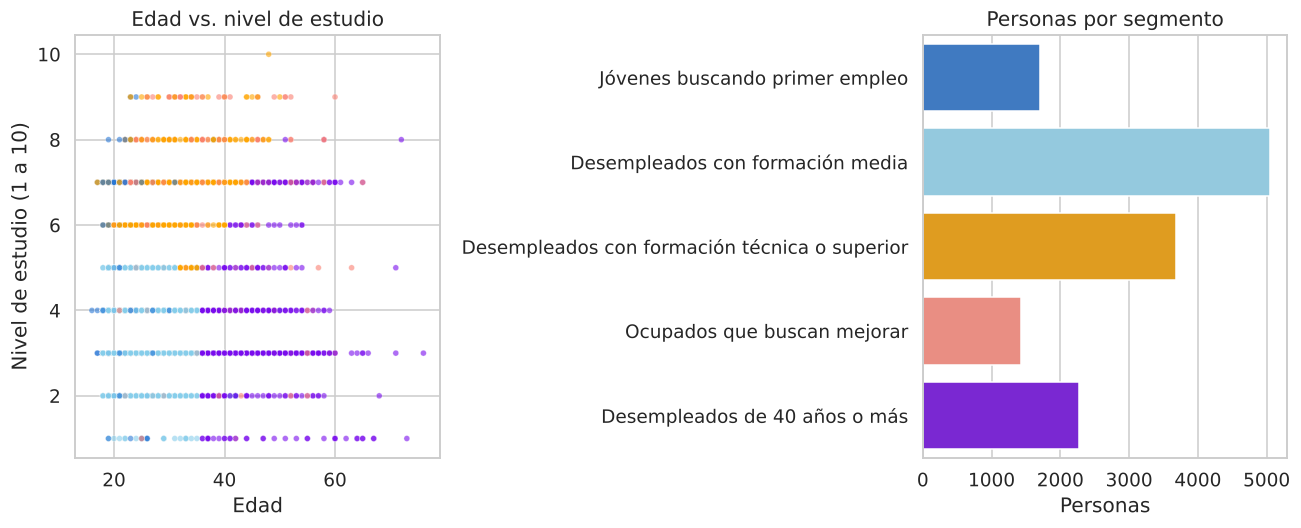

In [26]:
colores_seg = dict(zip(perfil["segmento"], [AZUL, "skyblue", "orange", "salmon", MORADO]))
muestra = perfiles.sample(4000, random_state=SEMILLA)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=muestra, x="edad", y="nivel_ord", hue="segmento", palette=colores_seg, s=15, alpha=0.6, legend=False, ax=axes[0])
axes[0].set(title="Edad vs. nivel de estudio", xlabel="Edad", ylabel="Nivel de estudio (1 a 10)")
sns.countplot(data=perfiles, y="segmento", hue="segmento", palette=colores_seg, order=perfil["segmento"], legend=False, ax=axes[1])
axes[1].set(title="Personas por segmento", xlabel="Personas", ylabel="")
plt.tight_layout()
guardar("fig11_segmentos")
plt.show()

**Acciones sugeridas por segmento**

| Segmento | Acción |
|---|---|
| Jóvenes buscando primer empleo | Ferias de primer empleo, formación en habilidades blandas, alianzas con instituciones educativas |
| Desempleados con formación media | Cursos cortos certificables y vacantes operativas |
| Desempleados con formación técnica o superior | Intermediación directa con vacantes calificadas |
| Desempleados de 40 años o más | Orientación laboral personalizada y empleadores con apertura a mayor edad |
| Ocupados que buscan mejorar | Servicio de movilidad laboral; baja prioridad frente a quienes no tienen empleo |

# 7 Exportación para el dashboard (Fase 3)

Se guardan los datos limpios y los puntajes de los modelos en `salidas/`. El dashboard interactivo (`dashboard.html`, y la versión Streamlit `app_streamlit.py`) los usa sin recalcular nada.

In [27]:
# Probabilidad de registro incompleto (logit) para todos los registros con fecha válida
p_incompleto = pd.Series(logit.predict_proba(X_total)[:, 1], index=X_total.index, name="prob_incompleto")

export = df.copy()
export = export.join(p_incompleto)
export = export.join(perfiles[["segmento"]])
columnas_export = [
    "periodo", "anio", "mes", "punto", "canal", "genero", "edad", "rango_edad", "nivel_estudio", "nivel_ord",
    "sit_laboral", "zona", "ciudad_g", "tiene_programa", "tiene_condicion", "hora", "dia_semana", "franja",
    "registro_util", "incompleto", "actualizo", "prob_incompleto", "segmento",
]
export[columnas_export].to_csv("salidas/registros_limpios.csv", index=False, encoding="utf-8")
print("Exportado salidas/registros_limpios.csv:", export[columnas_export].shape)

Exportado salidas/registros_limpios.csv: (23353, 23)


# 8 Fase 4: evaluación de decisiones

Se evalúan tres intervenciones con un mismo criterio: **costo por registro útil adicional**.

| Intervención | Qué hace | Evidencia que la respalda |
|---|---|---|
| **A. Validación obligatoria en el autoregistro** | El formulario no deja enviar sin situación laboral y nivel de estudio | Los registros asistidos son útiles en ~94 % y los autoregistros en ~48 % |
| **B. Seguimiento focalizado** | Contactar (llamada o mensaje) a los registros con mayor probabilidad de quedar incompletos | Modelo de clasificación (sección 5) |
| **C. Trasladar autoregistros a atención asistida** | Citar o atender a parte de quienes hoy se autoregistran | Diferencia de tasas por canal (sección 3.2) y efecto ajustado (sección 8.2) |

> **Supuestos de costo.** La base no trae costos ni valores monetarios. Los siguientes parámetros son **supuestos del grupo** (en pesos colombianos), marcados para poder cambiarlos y comprobar la sensibilidad del resultado: `V` valor de gestión de un registro útil, `C` costo de un contacto de seguimiento, `R` probabilidad de que el contacto complete el registro y `C_ASIST` costo de una atención asistida.

## 8.1 Intervención B: seguimiento focalizado y umbral de decisión

Punto de equilibrio: conviene contactar si P(incompleto) ≥ C / (V·R) = 0.33


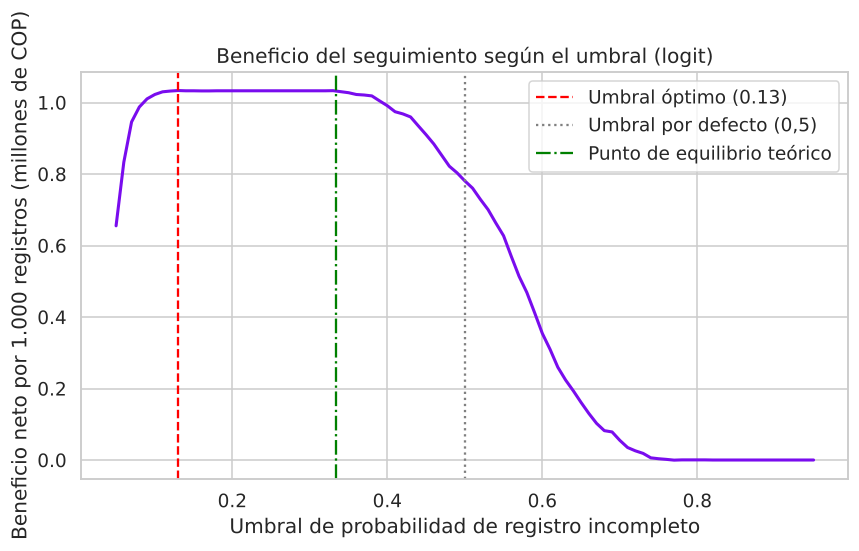

Beneficio por 1.000 registros (COP): umbral óptimo 1,033,486 · contactar a todos 461,231 · umbral 0,5 780,737
Regla sin modelo (contactar a todos los autoregistros): 1,032,772 por 1.000 registros
Umbral óptimo del modelo: contacta al 73% de los registros
AUC del logit solo entre autoregistros (más allá del canal): 0.601


In [28]:
# Supuestos (COP). Cámbielos para comprobar cómo varía la recomendación.
V = 25_000        # valor de gestión de un registro que pasa a ser útil
C = 2_500         # costo de un contacto de seguimiento (llamada o mensaje, ~5 minutos de un orientador)
R = 0.30          # probabilidad de que el contacto logre completar el registro
print(f"Punto de equilibrio: conviene contactar si P(incompleto) ≥ C / (V·R) = {C / (V * R):.2f}")

y_arr = np.asarray(y_prueba)
umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)


def beneficio(prob, y, u, V=V, C=C, R=R):
    # Beneficio neto de contactar a todos los registros con probabilidad >= u
    contactados = np.asarray(prob) >= u
    vp = (contactados & (y == 1)).sum()
    return V * R * vp - C * contactados.sum()


ben = np.array([beneficio(prob_logit, y_arr, u) for u in umbrales])
por_mil = 1000 / len(y_arr)
# Si varios umbrales dan el mismo beneficio (mismo grupo contactado), se toma el mayor
u_opt = umbrales[np.where(ben >= ben.max() - 1e-9)[0][-1]]
ben_todos = beneficio(prob_logit, y_arr, 0.0)
ben_05 = ben[umbrales == 0.5][0]

plt.figure(figsize=(9, 4.8))
plt.plot(umbrales, ben * por_mil / 1e6, color=MORADO, linewidth=2)
plt.axvline(u_opt, color="red", linestyle="--", label=f"Umbral óptimo ({u_opt:.2f})")
plt.axvline(0.5, color="gray", linestyle=":", label="Umbral por defecto (0,5)")
plt.axvline(C / (V * R), color="green", linestyle="-.", label="Punto de equilibrio teórico")
plt.title("Beneficio del seguimiento según el umbral (logit)")
plt.xlabel("Umbral de probabilidad de registro incompleto")
plt.ylabel("Beneficio neto por 1.000 registros (millones de COP)")
plt.legend()
guardar("fig12_umbral")
plt.show()

print(f"Beneficio por 1.000 registros (COP): umbral óptimo {ben.max() * por_mil:,.0f} · contactar a todos {ben_todos * por_mil:,.0f} · umbral 0,5 {ben_05 * por_mil:,.0f}")

# Referencia sin modelo: la regla simple "contactar a todos los autoregistros"
es_auto = X_prueba["autoregistro"].to_numpy() == 1
ben_regla = beneficio(es_auto.astype(float), y_arr, 1.0)
auc_dentro_auto = roc_auc_score(y_arr[es_auto], prob_logit[es_auto])
print(f"Regla sin modelo (contactar a todos los autoregistros): {ben_regla * por_mil:,.0f} por 1.000 registros")
print(f"Umbral óptimo del modelo: contacta al {(prob_logit >= u_opt).mean():.0%} de los registros")
print(f"AUC del logit solo entre autoregistros (más allá del canal): {auc_dentro_auto:.3f}")

### Capacidad limitada: ¿a quién contactar primero?

Si el equipo solo puede contactar a una fracción de los registros, el modelo sirve para **ordenar** a quién llamar. La tabla de ganancia acumulada compara contactar al azar con contactar según el puntaje.

In [29]:
orden = np.argsort(-prob_logit)
y_ord = y_arr[orden]
total_incompletos = y_arr.sum()
filas_g = []
for frac in [0.10, 0.20, 0.30, 0.40, 0.50]:
    n_c = int(frac * len(y_ord))
    capturados = y_ord[:n_c].sum()
    filas_g.append({
        "% de registros contactados": f"{frac:.0%}",
        "% de incompletos alcanzados (modelo)": capturados / total_incompletos,
        "% alcanzados al azar": frac,
        "lift": (capturados / total_incompletos) / frac,
        "precisión del contacto": capturados / n_c,
    })
ganancia = pd.DataFrame(filas_g).set_index("% de registros contactados")
ganancia

,% de incompletos alcanzados (modelo),% alcanzados al azar,lift,precisión del contacto
% de registros contactados,,,,
10%,0.169,0.1,1.693,0.669
20%,0.326,0.2,1.631,0.644
30%,0.470,0.3,1.566,0.619
40%,0.598,0.4,1.495,0.591
50%,0.715,0.5,1.429,0.564


## 8.2 Intervenciones A y C: escenarios sobre el canal

Para estimar cuánto mejoraría la tasa de registro útil si un autoregistro se convirtiera en registro asistido, se calcula un **efecto ajustado** con el logit: se toma a cada persona que se autoregistró, se le cambia el canal a "Agencia" dejando todo lo demás igual, y se compara su probabilidad de registro útil antes y después. Es más conservador que la diferencia simple de tasas porque controla por punto, horario, edad y año.

Aun así **no es un efecto causal**: quienes van a una agencia pueden ser distintos de quienes se autoregistran. Por eso en la simulación se descuenta el efecto con un factor de incertidumbre.

In [30]:
auto_mask = X_total["autoregistro"] == 1
X_contra = X_total[auto_mask].copy()
X_contra["autoregistro"] = 0
p_real = logit.predict_proba(X_total[auto_mask])[:, 1]       # P(incompleto) como autoregistro
p_contra = logit.predict_proba(X_contra)[:, 1]               # P(incompleto) si fuera atendido
uplift_ajustado = (p_real - p_contra).mean()                 # aumento en P(registro útil)

util_auto = df.loc[df["canal"] == "Autoregistro", "registro_util"].mean()
util_agencia = df.loc[df["canal"] == "Agencia", "registro_util"].mean()
uplift_bruto = util_agencia - util_auto
n_auto_mes = (df["canal"] == "Autoregistro").sum() / df["periodo"].nunique()
n_agencia_mes = (df["canal"] == "Agencia").sum() / df["periodo"].nunique()

print(f"Tasa útil autoregistro: {util_auto:.1%} · agencia: {util_agencia:.1%}")
print(f"Efecto bruto (diferencia simple): {uplift_bruto:+.1%} · efecto ajustado por el logit: {uplift_ajustado:+.1%}")
print(f"Autoregistros por mes: {n_auto_mes:,.0f} · atenciones asistidas por mes hoy: {n_agencia_mes:,.0f}")

Tasa útil autoregistro: 47.8% · agencia: 94.2%
Efecto bruto (diferencia simple): +46.5% · efecto ajustado por el logit: +44.8%
Autoregistros por mes: 530 · atenciones asistidas por mes hoy: 200


In [31]:
C_ASIST = 8_000    # costo de una atención asistida (COP), supuesto: ~20 min de un orientador con costos de apoyo
FACTOR = 0.7       # descuento del efecto por posible sesgo de selección (supuesto; se varía en la sensibilidad)


def escenario(share, uplift=uplift_ajustado, factor=FACTOR, c_asist=C_ASIST, v=V, n_auto=n_auto_mes):
    # Resultados mensuales de trasladar `share` de los autoregistros a atención asistida
    movidos = share * n_auto
    utiles_extra = movidos * uplift * factor
    costo = movidos * c_asist
    return {
        "% de autoregistros trasladados": share,
        "atenciones extra / mes": movidos,
        "registros útiles extra / mes": utiles_extra,
        "costo mensual (COP)": costo,
        "costo por útil adicional (COP)": costo / utiles_extra if utiles_extra > 0 else np.nan,
        "beneficio neto mensual (COP)": utiles_extra * v - costo,
        "aumento de carga de agencia": movidos / n_agencia_mes,
    }


tabla_escenarios = pd.DataFrame([escenario(s) for s in [0.0, 0.10, 0.20, 0.30, 0.50]]).set_index("% de autoregistros trasladados")
tabla_escenarios

,atenciones extra / mes,registros útiles extra / mes,costo mensual (COP),costo por útil adicional (COP),beneficio neto mensual (COP),aumento de carga de agencia
% de autoregistros trasladados,,,,,,
0.0,0.000,0.000,0.000e+00,NaN,0.000,0.000
0.1,52.994,16.601,4.240e+05,25537.343,-8920.521,0.265
0.2,105.988,33.202,8.479e+05,25537.343,-17841.043,0.530
0.3,158.981,49.804,1.272e+06,25537.343,-26761.564,0.796
0.5,264.969,83.006,2.120e+06,25537.343,-44602.607,1.326


In [32]:
# Escenario base para la intervención C vs. B (costo por registro útil adicional)
base = escenario(0.20)
costo_util_C = base["costo por útil adicional (COP)"]

# Para B: con el umbral óptimo, ¿cuánto cuesta cada registro que pasa a ser útil?
contactados = prob_logit >= u_opt
vp_b = (contactados & (y_arr == 1)).sum()
costo_util_B = C * contactados.sum() / (R * vp_b)

comparacion = pd.DataFrame({
    "intervención": ["A. Validación obligatoria en el formulario", "B. Seguimiento focalizado (modelo)", "C. Trasladar 20 % a atención asistida"],
    "costo por registro útil adicional (COP)": [np.nan, costo_util_B, costo_util_C],
    "comentario": [
        "Costo marginal bajo; el efecto se mide con un piloto A/B",
        f"Contacta al {contactados.mean():.0%} de los registros; costo por contacto C = {C:,}",
        f"Efecto descontado por factor {FACTOR}; añade {base['aumento de carga de agencia']:.0%} de carga a las agencias",
    ],
}).set_index("intervención")
c_equilibrio = uplift_ajustado * FACTOR * V
print(f"Costo por atención en el que la intervención C se paga sola: COP {c_equilibrio:,.0f} (supuesto actual: COP {C_ASIST:,})")
comparacion

Costo por atención en el que la intervención C se paga sola: COP 7,832 (supuesto actual: COP 8,000)


,costo por registro útil adicional (COP),comentario
intervención,,
A. Validación obligatoria en el formulario,NaN,Costo marginal bajo; el efecto se mide con un piloto A/B
B. Seguimiento focalizado (modelo),15957.646,"Contacta al 73% de los registros; costo por contacto C = 2,500"
C. Trasladar 20 % a atención asistida,25537.343,Efecto descontado por factor 0.7; añade 53% de carga a las agencias


## 8.3 Análisis de sensibilidad

La recomendación depende de supuestos. Se prueban tres cosas: (a) qué pasa si se cambia un supuesto a la vez (tornado), (b) cuánto varía el resultado al cambiar a la vez el costo de la atención y la proporción trasladada, y (c) una simulación Monte Carlo que combina la incertidumbre de todos los supuestos.

### (a) Tornado: un supuesto a la vez (escenario de 20 % trasladado)

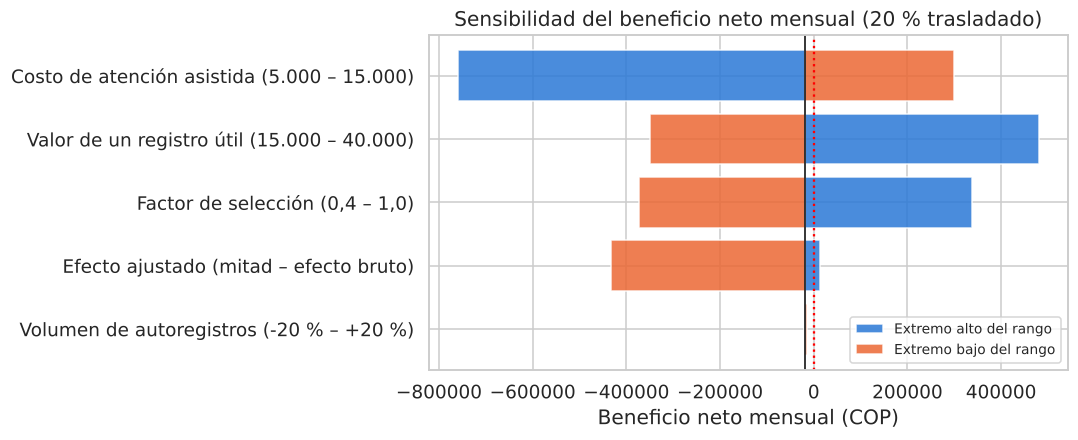

Beneficio neto mensual base (20 % trasladado): COP -17,841


,neto_con_valor_bajo,neto_con_valor_alto,rango
supuesto,,,
Volumen de autoregistros (-20 % – +20 %),-14272.834,-21409.251,7.136e+03
Efecto ajustado (mitad – efecto bruto),-432870.521,14210.443,4.471e+05
"Factor de selección (0,4 – 1,0)",-373580.596,337898.510,7.115e+05
Valor de un registro útil (15.000 – 40.000),-349864.626,480194.332,8.301e+05
Costo de atención asistida (5.000 – 15.000),300121.457,-759753.543,1.060e+06


In [33]:
base_neto = escenario(0.20)["beneficio neto mensual (COP)"]
variaciones = {
    "Costo de atención asistida (5.000 – 15.000)": ("c_asist", 5_000, 15_000),
    "Valor de un registro útil (15.000 – 40.000)": ("v", 15_000, 40_000),
    "Factor de selección (0,4 – 1,0)": ("factor", 0.4, 1.0),
    "Volumen de autoregistros (-20 % – +20 %)": ("n_auto", 0.8 * n_auto_mes, 1.2 * n_auto_mes),
    "Efecto ajustado (mitad – efecto bruto)": ("uplift", uplift_ajustado * 0.5, uplift_bruto),
}
filas_t = []
for nombre, (param, bajo, alto) in variaciones.items():
    r_bajo = escenario(0.20, **{param: bajo})["beneficio neto mensual (COP)"]
    r_alto = escenario(0.20, **{param: alto})["beneficio neto mensual (COP)"]
    filas_t.append({"supuesto": nombre, "neto_con_valor_bajo": r_bajo, "neto_con_valor_alto": r_alto,
                    "rango": abs(r_alto - r_bajo)})
tornado = pd.DataFrame(filas_t).sort_values("rango")

fig, ax = plt.subplots(figsize=(10, 4.2))
for i, fila in enumerate(tornado.itertuples()):
    ax.barh(i, fila.neto_con_valor_alto - base_neto, left=base_neto, color=AZUL, alpha=0.85, label="Extremo alto del rango" if i == 0 else None)
    ax.barh(i, fila.neto_con_valor_bajo - base_neto, left=base_neto, color=NARANJA, alpha=0.85, label="Extremo bajo del rango" if i == 0 else None)
ax.set_yticks(range(len(tornado)))
ax.set_yticklabels(tornado["supuesto"])
ax.axvline(base_neto, color="black", linewidth=1)
ax.axvline(0, color="red", linestyle=":")
ax.set(title="Sensibilidad del beneficio neto mensual (20 % trasladado)", xlabel="Beneficio neto mensual (COP)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
guardar("fig13_tornado")
plt.show()
print(f"Beneficio neto mensual base (20 % trasladado): COP {base_neto:,.0f}")
tornado.set_index("supuesto")

### (b) Mapa de calor: costo de la atención × proporción trasladada

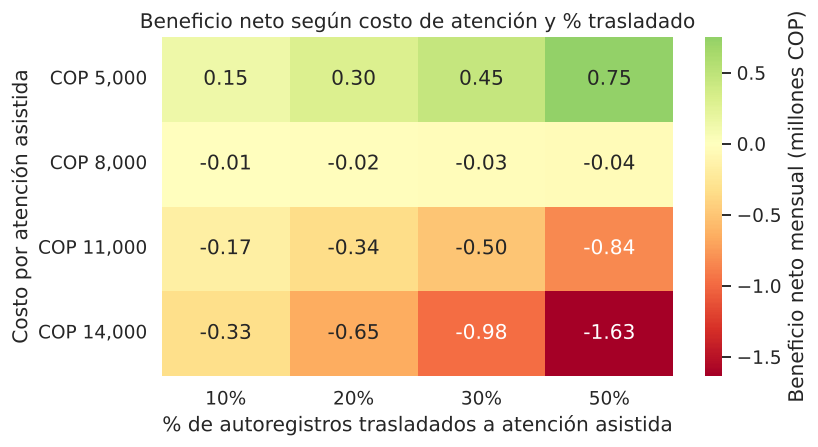

In [34]:
costos_grid = [5_000, 8_000, 11_000, 14_000]
shares_grid = [0.10, 0.20, 0.30, 0.50]
grid = pd.DataFrame(
    {f"{s:.0%}": [escenario(s, c_asist=c)["beneficio neto mensual (COP)"] / 1e6 for c in costos_grid] for s in shares_grid},
    index=[f"COP {c:,}" for c in costos_grid],
)
plt.figure(figsize=(7.5, 4))
sns.heatmap(grid, annot=True, fmt=".2f", cmap="RdYlGn", center=0, cbar_kws={"label": "Beneficio neto mensual (millones COP)"})
plt.title("Beneficio neto según costo de atención y % trasladado")
plt.xlabel("% de autoregistros trasladados a atención asistida")
plt.ylabel("Costo por atención asistida")
guardar("fig14_sensibilidad_grid")
plt.show()

### (c) Simulación Monte Carlo

Se sortean 10.000 combinaciones de supuestos con distribuciones razonables y se calcula el beneficio neto mensual del escenario de 20 % trasladado. Esto da un **rango** y la probabilidad de que el beneficio sea positivo.

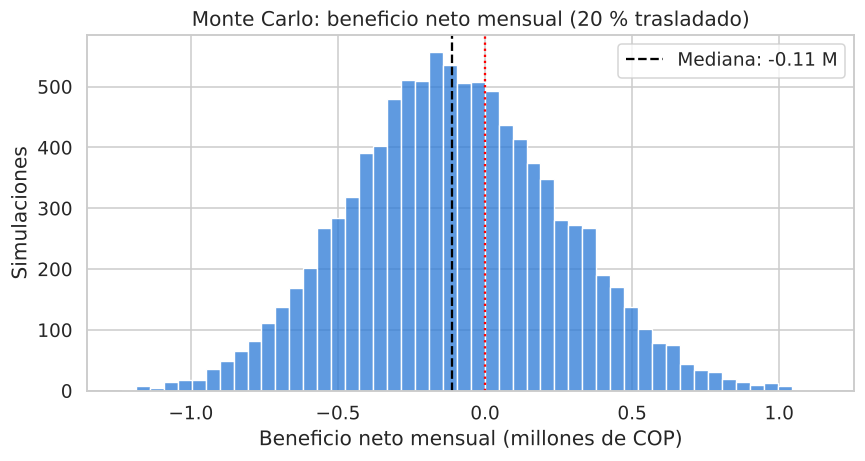

Mediana COP -111,377 · P5 COP -678,062 · P95 COP 497,136
Probabilidad de beneficio neto positivo: 38%


In [35]:
rng = np.random.default_rng(SEMILLA)
N_SIM = 10_000
sim = pd.DataFrame({
    "factor": rng.uniform(0.4, 1.0, N_SIM),
    "c_asist": rng.triangular(5_000, 8_000, 15_000, N_SIM),
    "v": rng.triangular(15_000, 25_000, 40_000, N_SIM),
    "n_auto": n_auto_mes * rng.normal(1.0, 0.10, N_SIM),
})
sim["neto"] = [escenario(0.20, factor=f, c_asist=c, v=v, n_auto=n)["beneficio neto mensual (COP)"]
               for f, c, v, n in zip(sim["factor"], sim["c_asist"], sim["v"], sim["n_auto"])]

p5, p50, p95 = sim["neto"].quantile([0.05, 0.50, 0.95])
prob_positivo = (sim["neto"] > 0).mean()

plt.figure(figsize=(9, 4.2))
sns.histplot(sim["neto"] / 1e6, bins=50, color=AZUL, edgecolor="white")
plt.axvline(0, color="red", linestyle=":")
plt.axvline(p50 / 1e6, color="black", linestyle="--", label=f"Mediana: {p50 / 1e6:.2f} M")
plt.title("Monte Carlo: beneficio neto mensual (20 % trasladado)")
plt.xlabel("Beneficio neto mensual (millones de COP)")
plt.ylabel("Simulaciones")
plt.legend()
guardar("fig15_montecarlo")
plt.show()

print(f"Mediana COP {p50:,.0f} · P5 COP {p5:,.0f} · P95 COP {p95:,.0f}")
print(f"Probabilidad de beneficio neto positivo: {prob_positivo:.0%}")

## 8.4 Dónde intervenir primero

Se prioriza por **autoregistros incompletos**: son los registros que la intervención puede recuperar. Combina volumen y tasa de falla.

In [36]:
prio = df[df["canal"] == "Autoregistro"].groupby("punto").agg(
    autoregistros=("canal", "size"),
    incompletos=("incompleto", "sum"),
    tasa_util=("registro_util", "mean"),
)
prio["pct_del_total_de_incompletos_auto"] = prio["incompletos"] / prio["incompletos"].sum() * 100
prio["incompletos_por_mes"] = prio["incompletos"] / df["periodo"].nunique()
prio = prio.sort_values("incompletos", ascending=False)
prio["acumulado_%"] = prio["pct_del_total_de_incompletos_auto"].cumsum()
prio

,autoregistros,incompletos,tasa_util,pct_del_total_de_incompletos_auto,incompletos_por_mes,acumulado_%
punto,,,,,,
Barrios San José,5197,2439,0.531,27.534,76.219,27.534
Barrio Simón Bolívar,4134,2381,0.424,26.880,74.406,54.414
Bario 7 de abril,3441,2173,0.368,24.531,67.906,78.946
Barrio Altos de Riomar,3539,1540,0.565,17.385,48.125,96.331
Barrios Modelo,647,325,0.498,3.669,10.156,100.000


## 8.5 Recomendación final

1. **Implementar de inmediato la validación obligatoria** de situación laboral y nivel de estudio en el autoregistro (intervención A). Ataca la causa principal, casi no tiene costo y su efecto se mide con un piloto A/B (la mitad de los usuarios con el formulario nuevo).
2. **Activar seguimiento focalizado** (intervención B) a los autoregistros incompletos mientras A no esté operando. Con los supuestos del grupo, cada registro recuperado cuesta menos que el valor que se le asigna (sección 8.2). El modelo sirve sobre todo para **ordenar** a quién llamar primero cuando la capacidad es limitada, y su ventaja sobre la regla simple por canal es modesta.
3. **No trasladar autoregistros a atención asistida de forma masiva** (intervención C). Con los supuestos actuales queda en el límite de rentabilidad: solo se paga si el costo por atención baja del punto de equilibrio calculado y exige una carga de agencia muy superior a la actual. Solo se justifica como piloto pequeño en los puntos con más autoregistros incompletos (sección 8.4).
4. **Medir y ajustar:** reportar mensualmente la tasa de registro útil por punto y canal (el dashboard ya lo hace), reestimar el modelo cada trimestre y sustituir los supuestos de costo por costos reales de la Secretaría.

# 9 Limitaciones

- La base **no incluye el resultado final** (si la persona consiguió empleo), por eso el proyecto mide calidad del registro y no efectividad en la colocación.
- Los costos y valores de las secciones 8.1 a 8.3 son **supuestos**; la recomendación se acompaña de análisis de sensibilidad para mostrar cuánto depende de ellos.
- La diferencia entre canales **no es causal**: puede haber sesgo de selección. Se mitiga con el efecto ajustado y un factor de descuento, pero solo un piloto lo confirma.
- Los datos terminan en **agosto de 2022**; conviene repetir el análisis con una extracción más reciente.
- Los umbrales óptimos se calcularon sobre la muestra de prueba, por lo que el beneficio puede estar algo sobreestimado.
- Se trabaja con una sola fuente. Integrar GEIH (desempleo), población DANE y SPE permitiría calcular tasas por habitante y contextualizar la demanda.
- No hay identificador de persona: un mismo individuo podría aparecer más de una vez (no se detectaron duplicados exactos).

In [37]:
# Guardar resultados clave para el documento y las diapositivas
import json

resultados = {
    "n_registros": int(len(df)),
    "tasa_util": float(util_global),
    "tasa_util_agencia": float(util_agencia),
    "tasa_util_autoregistro": float(util_auto),
    "pct_autoregistro": float((df["canal"] == "Autoregistro").mean()),
    "sit_informada": float(df["sit_informada"].mean()),
    "nivel_informado": float(df["nivel_informado"].mean()),
    "actualizo": float(df["actualizo"].mean()),
    "pct_prioritario": float(pct_prioritario),
    "chi2": float(chi2), "v_cramer": float(v_cramer),
    "beta_auto_10pp": float(beta_auto * 10),
    "ic_auto_10pp": [float(ic_auto[0] * 10), float(ic_auto[1] * 10)],
    "r2_panel": float(r2_reg), "n_panel": int(len(panel)),
    "modelo_demanda": mejor_demanda,
    "mape_total": float(mape_total), "mape_punto": float(mape_punto), "r2_demanda": float(r2_d),
    "or_auto": float(or_auto), "or_fin": float(or_fin),
    "auc": {k: float(v) for k, v in metricas["AUC"].items()},
    "u_opt": float(u_opt),
    "ben_regla_por_mil": float(ben_regla * por_mil),
    "auc_dentro_auto": float(auc_dentro_auto),
    "c_equilibrio": float(c_equilibrio),
    "pct_contactados_opt": float((prob_logit >= u_opt).mean()),
    "ben_opt_por_mil": float(ben.max() * por_mil),
    "ben_todos_por_mil": float(ben_todos * por_mil),
    "ben_05_por_mil": float(ben_05 * por_mil),
    "uplift_bruto": float(uplift_bruto), "uplift_ajustado": float(uplift_ajustado),
    "n_auto_mes": float(n_auto_mes), "n_agencia_mes": float(n_agencia_mes),
    "base_neto": float(base_neto),
    "mc": {"p5": float(p5), "p50": float(p50), "p95": float(p95), "prob_pos": float(prob_positivo)},
    "costo_util_B": float(costo_util_B), "costo_util_C": float(costo_util_C),
    "supuestos": {"V": V, "C": C, "R": R, "C_ASIST": C_ASIST, "FACTOR": FACTOR},
    "k": K,
}
with open("salidas/resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)

tabla_escenarios.to_csv("salidas/escenarios.csv")
ganancia.to_csv("salidas/ganancia.csv")
metricas.to_csv("salidas/metricas_modelos.csv")
perfil.set_index("segmento").to_csv("salidas/perfil_segmentos.csv")
prio.to_csv("salidas/prioridad_puntos.csv")
pareto.to_csv("salidas/pareto_puntos.csv")
tabla_reg.to_csv("salidas/regresion_canal.csv")
odds_ratios.to_csv("salidas/odds_ratios.csv")
futuro.groupby("periodo")["pronostico"].sum().to_csv("salidas/proyeccion_demanda.csv")
comparacion_demanda.to_csv("salidas/comparacion_demanda.csv")
tornado.to_csv("salidas/tornado.csv")
print("Resultados guardados en salidas/")

Resultados guardados en salidas/
